# RoadAware · ทุกขั้นตอนของโปรเจกต์ในโน้ตบุ๊กเดียว

**โจทย์:** คาดการณ์ว่า **ช่วงถนนไหน วันไหน ช่วงเวลาไหน** บนทางหลวงทั่วประเทศ มีโอกาสเกิดอุบัติเหตุมากกว่าที่อื่น เพื่อเตือนผู้ขับขี่ก่อนออกเดินทาง

โน้ตบุ๊กนี้ **รันกับข้อมูลจริงของโปรเจกต์** ทุกตัวเลขและทุกกราฟคำนวณใหม่ตอนรัน และตรวจเทียบกับผลของ pipeline จริงในแต่ละขั้น

| ขั้น | หัวข้อ | สิ่งที่ทำ | โน้ตบุ๊กต้นฉบับ |
|---|---|---|---|
| 1 | **Data Collection** | แหล่งข้อมูลทั้งหมด และหน้าตาข้อมูลดิบ | `01`, `09`, `17` |
| 2 | **Data Selection** | เลือกขอบเขต ปี ถนน หน่วยเวลา และคอลัมน์ที่ใช้ | `16`, `19` |
| 3 | **Data Cleaning** | แปลงวันที่และเวลา ตรวจพิกัด จัดการรหัสซ้ำ | `03`, `09`, `10`, `14` |
| 4 | **EDA** | สำรวจข้อมูล: เวลา ฤดู เทศกาล พื้นที่ สาเหตุ ความกระจุกตัว | `02` |
| 5 | **Data Preparation** | จับคู่กับถนน สร้างตารางเป้าหมาย สร้างตัวแปร | `18`, `19` |
| 6 | **Split Strategy** | แบ่งข้อมูลตามเวลา 4 รอบ | `20` |
| 7 | **Data Leakage** | วิธีกันข้อมูลอนาคตรั่วเข้าโมเดล | `19`, `20` |
| 8 | **Baseline + Model** | baseline และเทรน HistGradientBoosting (Poisson) จริง | `20` |
| 9 | **Evaluation** | Poisson deviance, เทียบ baseline, calibration | `20`, `21` |
| 10 | **Error Analysis** | ทำนายพลาดตรงไหน ช่วงเวลา ฤดู เทศกาล | `20`, `21` |
| 11 | **Model Selection** | เกณฑ์ 3 ข้อที่ล็อกไว้ก่อน และสีบนแผนที่ | `20`, `21` |
| 12 | **ทดสอบปี 2569** | ผลกับข้อมูลที่โมเดลไม่เคยเห็น | `23` |

**วิธีรัน:** เลือก kernel `.venv` ของโปรเจกต์ แล้วกด **Run All** (ประมาณ 5–10 นาที ส่วนที่นานที่สุดคือขั้น 8–9 ที่เทรนและทำนาย 19.7 ล้านช่อง)

> 💡 กล่องแบบนี้อธิบายว่า **"ทำไม"** ถึงทำแบบนั้น ซึ่งเป็นคำถามที่มักโดนถามตอนนำเสนอ

## 0 · เตรียมเครื่องมือ
- `pandas`, `numpy` สำหรับจัดการตาราง
- `scikit-learn` สำหรับโมเดล
- `matplotlib` สำหรับกราฟ

เซลล์นี้หาโฟลเดอร์โปรเจกต์ให้อัตโนมัติ ตั้งฟอนต์ภาษาไทยและสีของกราฟให้เหมือนหน้าเว็บ และสร้างฟังก์ชันช่วยวาดกราฟ

In [1]:
from pathlib import Path
import json, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown

# แสดงตารางได้สูงสุด 40 คอลัมน์ และกว้าง 160 ตัวอักษร
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# หาโฟลเดอร์โปรเจกต์: ไล่ขึ้นจากโฟลเดอร์ปัจจุบันจนเจอไฟล์ config ของโปรเจกต์
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "backend/config/spatial_experiment_v4.json").is_file())
B = REPO / "backend"
RAW = B / "data/raw/accidents"                      # ไฟล์อุบัติเหตุต้นฉบับ (กระทรวงคมนาคม)
PREP = B / "data/v4/spatial_preparation"            # ผลของโน้ตบุ๊ก 19 (ทั้งประเทศ)
LINK = B / "data/v4/linkage_audit"                  # ผลของโน้ตบุ๊ก 18
RUN20 = B / "rerun-spatial-model-national-20261120-150631/reports/v4/spatial_experiments"   # ผลทางการโน้ตบุ๊ก 20
RUN21 = B / "rerun-spatial-eval-national-20261120-160533/reports/v4/spatial_evaluation"     # ผลทางการโน้ตบุ๊ก 21
RUN23 = B / "rerun-2026-eval-national-20261125-084442/reports/v4/evaluation_2026"          # ผลทดสอบปี 2569
# อ่านค่าตั้งของการทดลอง (โมเดล การสุ่ม เกณฑ์) ไฟล์เดียวกับที่โน้ตบุ๊ก 20 ใช้
EXP = json.loads((B / "config/spatial_experiment_v4.json").read_text("utf-8"))

# ---- ฟอนต์ไทย + สีชุดเดียวกับเว็บ ----
# รายชื่อฟอนต์ที่มีในเครื่อง แล้วเลือกฟอนต์ไทยตัวแรกที่มี
_have = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Thonburi", "Sukhumvit Set", "Tahoma", "Leelawadee UI", "Noto Sans Thai", "Loma"]:
    if name in _have:
        plt.rcParams["font.family"] = name
        break
# สีของกราฟ ใช้ชุดเดียวกับหน้าเว็บ
NAVY, BLUE, LIGHT, AMBER, RED, GREY = "#0F1B2D", "#2D5A93", "#9DB4D3", "#E8821E", "#C0392B", "#B7BDC6"
# ตั้งค่ากราฟ: ขนาดตัวอักษร เส้นตาราง ไม่มีกรอบด้านบน/ขวา
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8A93A0",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12, "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "axes.grid": True, "grid.color": "#E3E6EB", "grid.linewidth": .8,
    "axes.axisbelow": True, "axes.unicode_minus": False, "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=[BLUE, AMBER, GREY, RED, NAVY]),
})
# ชื่อเดือนและวันภาษาไทย ใช้เป็นป้ายแกน
TH_MONTH = ["ม.ค.", "ก.พ.", "มี.ค.", "เม.ย.", "พ.ค.", "มิ.ย.", "ก.ค.", "ส.ค.", "ก.ย.", "ต.ค.", "พ.ย.", "ธ.ค."]
TH_DOW = ["จันทร์", "อังคาร", "พุธ", "พฤหัสฯ", "ศุกร์", "เสาร์", "อาทิตย์"]
# ช่วงเวลา 6 ชม. ทั้ง 4 ช่วง
BLOCKS = ["00-06", "06-12", "12-18", "18-24"]
BLOCK_TH = {"00-06": "00–06 น.", "06-12": "06–12 น.", "12-18": "12–18 น.", "18-24": "18–24 น."}

# ฟังก์ชันช่วย: ใส่จุลภาคให้ตัวเลขบนแกน (เช่น 20,000)
def commas(ax, axis="y"):
    f = FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)

# ฟังก์ชันช่วย: เขียนตัวเลขบนแท่งกราฟ
def label_bars(ax, fmt="{:,.0f}", horizontal=False, size=9, color="#33404F", pad=3):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if not np.isfinite(v) or v == 0:
            continue
        if horizontal:
            ax.annotate(fmt.format(v), (p.get_x() + v, p.get_y() + p.get_height() / 2), xytext=(pad, 0),
                        textcoords="offset points", va="center", fontsize=size, color=color)
        else:
            ax.annotate(fmt.format(v), (p.get_x() + p.get_width() / 2, v), xytext=(0, pad),
                        textcoords="offset points", ha="center", fontsize=size, color=color)

# ฟังก์ชันช่วย: เขียนหมายเหตุใต้กราฟ
def note(ax, text):
    ax.text(0, -0.2, text, transform=ax.transAxes, fontsize=9, color="#6B7686", va="top")

print("โฟลเดอร์โปรเจกต์:", REPO)
print("ฟอนต์กราฟ:", plt.rcParams["font.family"])

โฟลเดอร์โปรเจกต์: /mnt/user-data/uploads/RoadAware
ฟอนต์กราฟ: ['Loma']


---
# 1 · Data Collection — แหล่งข้อมูล

| ข้อมูล | แหล่ง | ใช้ทำอะไร | ขนาดที่เก็บได้ |
|---|---|---|---|
| **อุบัติเหตุบนถนน** 2564–2569 | กระทรวงคมนาคม (datagov.mot.go.th) | **ตัวหลัก** ใช้เป็นเป้าหมาย (y) | 6 ไฟล์ · 62 MB · 112,136 แถว (2564–2568) |
| **เส้นทางหลวง** | Transport GIS กระทรวงคมนาคม (ArcGIS FeatureServer) | ตัดถนนเป็นช่วง 2 กม. และตัวแปรรูปร่างถนน | กรมทางหลวง 159 ไฟล์ · 137 MB (+ ทางหลวงชนบท / ทางพิเศษ ใช้ตรวจ) |
| **ปริมาณจราจร (AADT)** | กรมทางหลวง (opendata.doh.go.th) | ตัวแปรปริมาณรถ | 6 ไฟล์ · 4 MB (ปี 2563–2568) |
| **สภาพอากาศ** | Open-Meteo (แบบจำลอง JMA GSM) | ฝนและอุณหภูมิที่พยากรณ์ล่วงหน้า | 42 ไฟล์ · 50 MB (ปี 2564–2566) |
| **วันหยุด** | ธนาคารแห่งประเทศไทย | ตัวแปรวันหยุด | 13 ไฟล์ · 11 MB |

> 💡 **ทำไมใช้ข้อมูลอุบัติเหตุของกระทรวงคมนาคม:** เป็นข้อมูลเปิดที่มี **พิกัดของแต่ละเหตุ** จึงระบุได้ว่าเกิดบนถนนช่วงไหน ซึ่งจำเป็นสำหรับการทำนายรายช่วงถนน

,ปี พ.ศ.,จำนวนแถว,จำนวนคอลัมน์,ขนาดไฟล์ (MB)
0,2564,20062,38,10.4
1,2565,20566,38,10.6
2,2566,23841,38,12.1
3,2567,23952,38,11.3
4,2568,23715,38,12.0


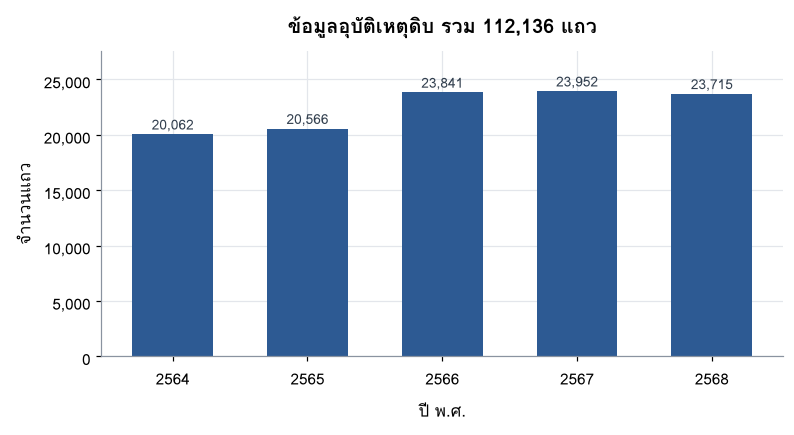

In [2]:
# ปีที่ใช้ฝึกและตรวจ (ปี 2569 เก็บไว้ทดสอบ)
YEARS_BE = [2564, 2565, 2566, 2567, 2568]

def read_raw(year_be):
    # อ่านทุกคอลัมน์เป็นข้อความ (dtype=str) ก่อน เพื่อไม่ให้ pandas เดารูปแบบวันที่และตัวเลขเอง
    # อ่านไฟล์ CSV ต้นฉบับ (utf-8-sig ตัด BOM ที่หัวไฟล์ออก)
    df = pd.read_csv(RAW / f"accidents_{year_be}_original.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
    # ตัดช่องว่างในชื่อคอลัมน์
    df.columns = [c.strip() for c in df.columns]
    # บันทึกปีของไฟล์
    df["be_year"] = year_be
    df["source_row"] = np.arange(2, len(df) + 2)      # เลขแถวในไฟล์จริง ใช้ตามรอยกลับไปต้นฉบับ
    return df

# อ่านทั้ง 5 ปี เก็บเป็น dict: ปี → ตาราง
raw = {y: read_raw(y) for y in YEARS_BE}
# ตารางสรุป: จำนวนแถว คอลัมน์ ขนาดไฟล์ ของแต่ละปี
inv = pd.DataFrame([{"ปี พ.ศ.": y, "จำนวนแถว": len(d), "จำนวนคอลัมน์": d.shape[1] - 2,
                     "ขนาดไฟล์ (MB)": round((RAW / f"accidents_{y}_original.csv").stat().st_size / 1e6, 1)} for y, d in raw.items()])
display(inv)

# กราฟแท่งจำนวนแถวต่อปี
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(inv["ปี พ.ศ."].astype(str), inv["จำนวนแถว"], color=BLUE, width=.6)
label_bars(ax); commas(ax)
ax.set_title(f"ข้อมูลอุบัติเหตุดิบ รวม {inv['จำนวนแถว'].sum():,} แถว"); ax.set_xlabel("ปี พ.ศ."); ax.set_ylabel("จำนวนแถว")
ax.set_ylim(0, inv["จำนวนแถว"].max() * 1.15)
plt.show()

### 1.1 หน้าตาข้อมูลดิบ

ไฟล์มี 38 คอลัมน์ ตัวอย่างคอลัมน์สำคัญ:

In [3]:
# แสดงตัวอย่าง 5 แถวแรกของปี 2566 เฉพาะคอลัมน์สำคัญ
display(raw[2566][["ACC_CODE", "วันที่เกิดเหตุ", "เวลา", "รหัสสายทาง", "KM", "จังหวัด", "LATITUDE", "LONGITUDE",
                   "ลักษณะการเกิดเหตุ", "มูลเหตุสันนิษฐาน", "ผู้เสียชีวิต"]].head(5))
print("คอลัมน์ทั้งหมด:", list(raw[2566].columns[:38]))

คอลัมน์ทั้งหมด: ['ปีที่เกิดเหตุ', 'วันที่เกิดเหตุ', 'เวลา', 'วันที่รายงาน', 'เวลาที่รายงาน', 'ACC_CODE', 'หน่วยงาน', 'สายทางหน่วยงาน', 'รหัสสายทาง', 'สายทาง', 'KM', 'จังหวัด', 'รถคันที่1', 'บริเวณที่เกิดเหตุ', 'มูลเหตุสันนิษฐาน', 'ลักษณะการเกิดเหตุ', 'สภาพอากาศ', 'LATITUDE', 'LONGITUDE', 'รถที่เกิดเหตุ', 'รถและคนที่เกิดเหตุ', 'รถจักรยานยนต์', 'รถสามล้อเครื่อง', 'รถยนต์นั่งส่วนบุคคล', 'รถตู้', 'รถปิคอัพโดยสาร', 'รถโดยสารมากกว่า4ล้อ', 'รถปิคอัพบรรทุก4ล้อ', 'รถบรรทุก6ล้อ', 'รถบรรทุกไม่เกิน10ล้อ', 'รถบรรทุกมากกว่า10ล้อ', 'รถอีแต๋น', 'รถอื่นๆ', 'คนเดินเท้า', 'ผู้เสียชีวิต', 'ผู้บาดเจ็บสาหัส', 'ผู้บาดเจ็บเล็กน้อย', 'รวมจำนวนผู้บาดเจ็บ']


,ACC_CODE,วันที่เกิดเหตุ,เวลา,รหัสสายทาง,KM,จังหวัด,LATITUDE,LONGITUDE,ลักษณะการเกิดเหตุ,มูลเหตุสันนิษฐาน,ผู้เสียชีวิต
0,7542138,1/1/2023,0:01,รน.4038,0.07,ระนอง,9.958841,98.652833,เสียหลัก ตกถนนโค้งซ้าย,หลับใน,0
1,7542110,1/1/2023,0:05,สส.5007,0.7,สมุทรสงคราม,13.455661,100.044082,เสียหลัก ตกถนนชนวัตถุทางขวา,เมาสุรา,0
2,8548373,1/1/2023,0:05,4009,95,สุราษฎร์ธานี,8.568017335,99.11665544,พลิกคว่ำ/ตกถนนในทางโค้ง,ขับรถเร็วเกินอัตราที่กำหนด,0
3,7615338,1/1/2023,0:07,2005,5.5,เพชรบูรณ์,16.91159259,101.1916045,ชนในทิศทางตรงกันข้าม (ไม่ใช่การแซง),ขับรถเร็วเกินอัตราที่กำหนด,1
4,7536059,1/1/2023,0:10,1112,3,กำแพงเพชร,15.97965797,99.78557912,ชนคนเดินเท้า,ขับรถเร็วเกินอัตราที่กำหนด,1


---
# 2 · Data Selection — เลือกขอบเขตข้อมูล

| ตัดสินใจ | เลือก | เหตุผล |
|---|---|---|
| **ปี** | ฝึกและตรวจ 2564–2568 · ทดสอบ 2569 | ใช้ข้อมูลอดีตฝึก แล้วเก็บปีล่าสุดไว้ทดสอบจริง |
| **ถนน** | ทางหลวงของ **กรมทางหลวง** (สายมาตรฐาน) | มีเส้นทางและเลขสายทางครบ จับคู่กับจุดเกิดเหตุได้แม่น |
| **หน่วยพื้นที่** | **ช่วงถนนละ 2 กม.** (26,740 ช่วง) | ละเอียดพอจะชี้จุดบนเส้นทาง แต่ยังมีข้อมูลพอให้เรียนรู้ |
| **หน่วยเวลา** | **รายวัน** และ **ราย 6 ชม.** (00–06, 06–12, 12–18, 18–24) | ความเสี่ยงต่างกันตามช่วงเวลาของวัน |
| **สิ่งที่ทำนาย** | จำนวนอุบัติเหตุที่ถูกบันทึกต่อช่องเวลา | ข้อมูลเป็นจำนวนนับ จึงใช้โมเดลแบบ Poisson |

### 2.1 คอลัมน์ที่ใช้ และไม่ใช้

In [4]:
# ตารางว่าคอลัมน์ไหนใช้ คอลัมน์ไหนไม่ใช้ และเหตุผล
cols = pd.DataFrame([
    ["ACC_CODE", "ใช้", "ตรวจแถวซ้ำ"],
    ["วันที่เกิดเหตุ, เวลา", "ใช้", "นับจำนวนต่อวัน และต่อช่วง 6 ชม."],
    ["LATITUDE, LONGITUDE", "ใช้", "จับคู่กับช่วงถนน"],
    ["รหัสสายทาง, KM, จังหวัด", "ใช้ตรวจ", "ตรวจว่าจับคู่ถูกสาย และตรวจความครบถ้วน"],
    ["ลักษณะการเกิดเหตุ, มูลเหตุสันนิษฐาน, รถคันที่1, สภาพอากาศ", "ไม่ใช้เป็นตัวแปร", "รู้หลังเกิดเหตุแล้ว (ใช้แค่ใน EDA และหน้าเว็บ)"],
    ["ผู้เสียชีวิต, ผู้บาดเจ็บ", "ไม่ใช้เป็นตัวแปร", "เป็นผลของเหตุ ถ้าใส่จะเป็นการโกง (leakage)"],
], columns=["คอลัมน์", "การใช้", "เหตุผล"])
display(cols)

,คอลัมน์,การใช้,เหตุผล
0,ACC_CODE,ใช้,ตรวจแถวซ้ำ
1,"วันที่เกิดเหตุ, เวลา",ใช้,นับจำนวนต่อวัน และต่อช่วง 6 ชม.
2,"LATITUDE, LONGITUDE",ใช้,จับคู่กับช่วงถนน
3,"รหัสสายทาง, KM, จังหวัด",ใช้ตรวจ,ตรวจว่าจับคู่ถูกสาย และตรวจความครบถ้วน
4,"ลักษณะการเกิดเหตุ, มูลเหตุสันนิษฐาน, รถคันที่1...",ไม่ใช้เป็นตัวแปร,รู้หลังเกิดเหตุแล้ว (ใช้แค่ใน EDA และหน้าเว็บ)
5,"ผู้เสียชีวิต, ผู้บาดเจ็บ",ไม่ใช้เป็นตัวแปร,เป็นผลของเหตุ ถ้าใส่จะเป็นการโกง (leakage)


> 💡 **ทำไมไม่ใช้สาเหตุหรือสภาพอากาศที่บันทึกในรายงานเป็นตัวแปร:** ตอนทำนาย (ก่อนเดินทาง) เรายังไม่รู้ค่าเหล่านี้ ถ้าใส่เข้าไป โมเดลจะดูแม่นตอนทดสอบ แต่ใช้งานจริงไม่ได้

---
# 3 · Data Cleaning — ทำความสะอาดข้อมูล

### 3.1 ปัญหาที่เจอ: วันที่และเวลาแต่ละปีเขียนไม่เหมือนกัน

In [5]:
rows = []
for y, d in raw.items():
    s = d["วันที่เกิดเหตุ"]
    # เก็บตัวอย่างวันที่/เวลา และนับว่าแต่ละปีใช้รูปแบบไหนกี่แถว
    rows.append({"ปี พ.ศ.": y, "ตัวอย่างวันที่": ", ".join(s.iloc[[0, 400, 6000]]),
                 "ตัวอย่างเวลา": ", ".join(d["เวลา"].iloc[[0, 400, 6000]]),
                 "วันที่เป็นเลข Excel": int(s.str.fullmatch(r"\d+").sum()),
                 "วันที่แบบ a/b/ปี": int(s.str.contains("/").sum()),
                 "เวลาเป็นเศษส่วนของวัน": int(d["เวลา"].str.fullmatch(r"0?\.\d+").sum())})
display(pd.DataFrame(rows))

,ปี พ.ศ.,ตัวอย่างวันที่,ตัวอย่างเวลา,วันที่เป็นเลข Excel,วันที่แบบ a/b/ปี,เวลาเป็นเศษส่วนของวัน
0,2564,"1/1/2021, 1/2/2021, 4/5/2021","0:00, 14:30, 12:20",0,20062,0
1,2565,"01/01/2022, 02/01/2022, 12/04/2022","0:01, 12:30, 17:25",0,20566,0
2,2566,"1/1/2023, 1/2/2023, 4/1/2023","0:01, 12:20, 7:15",0,23841,0
3,2567,"45292, 45293, 45373","0.008333333, 0.645833333, 0.722222222",23952,0,23912
4,2568,"45658, 45659, 45744","0:00, 20:30, 0:00",23715,0,0


- **2564–2566** ส่วนใหญ่เขียน `เดือน/วัน/ปี` (เช่น `1/2/2023` = 2 ม.ค.) แต่ **ปี 2565 บางช่วงเขียนสลับเป็น `วัน/เดือน/ปี`** (เช่น `12/04/2022` = 12 เม.ย.)
- **2567–2568** วันที่เป็น **เลขลำดับวันของ Excel** (เช่น `45292` = 1 ม.ค. 2024)
- **2567** เวลาเป็น **เศษส่วนของวัน** (เช่น `0.5` = 12:00)

> 💡 `1/2/2023` อ่านได้ทั้ง 1 ก.พ. และ 2 ม.ค. ถ้าใช้ `pd.to_datetime` ตรง ๆ จะเดาผิดโดยไม่มี error เตือน และข้อมูลเทศกาลกับฤดูกาลจะผิดทั้งชุด

### 3.2 แปลงวันที่ (`parse_date` · โน้ตบุ๊ก 03 cell 3)
1. **เลข Excel** → นับวันต่อจาก 30 ธ.ค. 1899
2. **a/b/ปี** → ลองอ่านทั้งสองแบบ (ถ้าปี > 2400 เป็น พ.ศ. ให้ลบ 543)
   - อ่านได้แบบเดียว (เช่น `01/13/2022` เพราะไม่มีเดือน 13) → ใช้แบบนั้น
   - อ่านได้ทั้งสองแบบ → ไฟล์เรียงตามวันที่ จึงเลือกแบบที่ใกล้แถวข้างเคียง (pipeline จริงใช้ไฟล์ XLSX ต้นฉบับของกระทรวงตัดสิน ในโน้ตบุ๊ก 09–10 ซึ่งได้ผลตรงกัน 100%)
3. วันที่ไม่ตรงกับปีของไฟล์ → ถือว่าผิด

,2564,2565,2566,2567,2568
date_how,,,,,
a/b/ปี (อ่านได้แบบเดียว),12649,13298,15546,0,0
a/b/ปี (กำกวม: เลือกตามแถวข้างเคียง),7413,7268,8295,0,0
เลข Excel,0,0,0,23952,23715


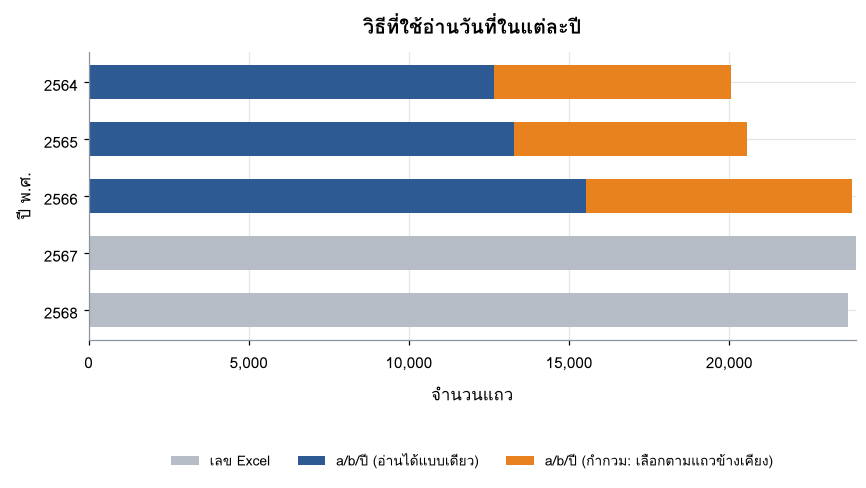

In [6]:
# วันเริ่มนับของเลขวันที่ Excel
EXCEL_ORIGIN = pd.Timestamp("1899-12-30")

def parse_dates(s, year_ce):
    # ผลลัพธ์ เริ่มเป็นค่าว่าง (NaT)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    # บันทึกวิธีที่ใช้อ่านแต่ละแถว
    how = pd.Series("อ่านไม่ได้", index=s.index, dtype=object)
    # แถวที่เป็นตัวเลขล้วน = เลข Excel
    serial = s.str.fullmatch(r"\d+(\.0+)?")
    # แปลงเป็นตัวเลข
    n = pd.to_numeric(s.where(serial), errors="coerce")
    # เลข Excel ที่สมเหตุสมผล (ปี 1982–2064)
    ok = serial & n.between(30000, 60000)
    # วันที่ = 30 ธ.ค. 1899 + n วัน
    out[ok] = EXCEL_ORIGIN + pd.to_timedelta(n[ok], unit="D")
    how[ok] = "เลข Excel"
    # แถวรูปแบบ a/b/ปี
    slash = s.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}")
    if slash.any():
        # แยกเป็น 3 ส่วน
        p = s.where(slash).str.split("/", expand=True)
        a, b, y = (pd.to_numeric(p[i], errors="coerce") for i in range(3))
        # ปี พ.ศ. → ค.ศ.
        y = y.where(y < 2400, y - 543)
        # อ่านแบบ เดือน/วัน/ปี (อ่านไม่ได้จะเป็น NaT)
        mdy = pd.to_datetime(dict(year=y, month=a, day=b), errors="coerce")
        # อ่านแบบ วัน/เดือน/ปี
        dmy = pd.to_datetime(dict(year=y, month=b, day=a), errors="coerce")
        # อ่านได้แบบเดือน/วันเท่านั้น (หรือทั้งสองแบบได้วันเดียวกัน)
        only_mdy = slash & mdy.notna() & (dmy.isna() | (mdy == dmy))
        # อ่านได้แบบวัน/เดือนเท่านั้น
        only_dmy = slash & dmy.notna() & mdy.isna()
        out[only_mdy], how[only_mdy] = mdy[only_mdy], "a/b/ปี (อ่านได้แบบเดียว)"
        out[only_dmy], how[only_dmy] = dmy[only_dmy], "a/b/ปี (อ่านได้แบบเดียว)"
        # อ่านได้ทั้ง 2 แบบและได้คนละวัน = กำกวม
        both = slash & mdy.notna() & dmy.notna() & (mdy != dmy)
        # วันที่อ้างอิง = วันที่ของแถวข้างเคียงที่ไม่กำกวม (ไฟล์เรียงตามวันที่)
        ref = out.where(~both).ffill().bfill()
        # เลือกแบบวัน/เดือน ถ้าใกล้วันอ้างอิงมากกว่า
        pick_dmy = (dmy - ref).abs() < (mdy - ref).abs()
        # ใส่วันที่ที่เลือกให้แถวกำกวม
        out[both] = np.where(pick_dmy[both], dmy[both], mdy[both])
        how[both] = "a/b/ปี (กำกวม: เลือกตามแถวข้างเคียง)"
    # วันที่ที่ปีไม่ตรงกับไฟล์ ถือว่าผิด
    bad = out.notna() & (out.dt.year != year_ce)
    out[bad], how[bad] = pd.NaT, "ปีไม่ตรงกับไฟล์"
    return out, how

how_all = []
for y, d in raw.items():
    # แปลงวันที่ของแต่ละปี (ส่งปี ค.ศ. ของไฟล์เข้าไปตรวจ)
    d["event_date"], d["date_how"] = parse_dates(d["วันที่เกิดเหตุ"], y - 543)
    how_all.append(d["date_how"].value_counts().rename(y))
# ตารางสรุปวิธีอ่านวันที่ แยกตามปี
how_tab = pd.concat(how_all, axis=1).fillna(0).astype(int)
display(how_tab)

fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(YEARS_BE))
colors = {"เลข Excel": GREY, "a/b/ปี (อ่านได้แบบเดียว)": BLUE, "a/b/ปี (กำกวม: เลือกตามแถวข้างเคียง)": AMBER}
for k, c in colors.items():
    v = how_tab.reindex(index=[k]).fillna(0).to_numpy().ravel() if k in how_tab.index else np.zeros(len(YEARS_BE))
    ax.barh([str(y) for y in YEARS_BE], v, left=left, color=c, label=k, height=.6)
    left += v
commas(ax, "x"); ax.invert_yaxis(); ax.set_xlabel("จำนวนแถว"); ax.set_ylabel("ปี พ.ศ.")
ax.set_title("วิธีที่ใช้อ่านวันที่ในแต่ละปี"); ax.legend(loc="lower center", bbox_to_anchor=(.5, -.5), ncol=3, fontsize=9)
plt.show()

### 3.3 แปลงเวลา และจัดเข้าช่วง 6 ชั่วโมง
- `H:MM` อ่านตรง ๆ
- ตัวเลข 0–1 คือเศษส่วนของ 1 วัน ให้คูณ 86,400 เป็นวินาที
- ถ้าปัดแล้วได้ 24:00 ถือว่าผิด เพราะวันที่จะเลื่อนไปอีกวัน

In [7]:
def parse_seconds(s):
    # ผลลัพธ์: วินาทีนับจากเที่ยงคืน
    sec = pd.Series(np.nan, index=s.index)
    # แยกชั่วโมง นาที วินาที จากรูปแบบ H:MM(:SS)
    hm = s.str.extract(r"^(\d{1,2}):(\d{2})(?::(\d{2}))?$").astype(float)
    # ตรวจว่าชั่วโมง < 24 และนาที/วินาที < 60
    ok = hm[0].lt(24) & hm[1].lt(60) & hm[2].fillna(0).lt(60)
    # แปลงเป็นวินาที
    sec[ok] = hm[0][ok] * 3600 + hm[1][ok] * 60 + hm[2].fillna(0)[ok]
    # แถวที่เหลือ ลองอ่านเป็นเศษส่วนของวัน (ไฟล์ปี 2567)
    frac = pd.to_numeric(s.where(~ok), errors="coerce")
    # ต้องอยู่ในช่วง 0 ถึงน้อยกว่า 1 และปัดแล้วไม่เป็น 24:00
    fok = frac.ge(0) & frac.lt(1) & (np.round(frac * 86400) < 86400)
    # แปลงเป็นวินาที (1 วัน = 86,400 วินาที)
    sec[fok] = np.round(frac[fok] * 86400)
    return sec

for y, d in raw.items():
    d["seconds"] = parse_seconds(d["เวลา"])
    # ชั่วโมงที่เกิดเหตุ (ใช้ใน EDA)
    d["hour"] = (d["seconds"] // 3600)
    # จัดเข้าช่วง 6 ชม.: 0–21600 วินาที = 00-06 เป็นต้น
    d["time_block"] = pd.cut(d["seconds"], [0, 21600, 43200, 64800, 86400], right=False, labels=BLOCKS).astype(object)
print("เวลาที่อ่านไม่ได้:", {y: int(d["seconds"].isna().sum()) for y, d in raw.items()})
print("ตัวอย่างปี 2567 (เวลาเป็นเศษส่วน):")
display(raw[2567][["เวลา", "seconds", "time_block"]].head(4))

เวลาที่อ่านไม่ได้: {2564: 0, 2565: 0, 2566: 0, 2567: 0, 2568: 0}
ตัวอย่างปี 2567 (เวลาเป็นเศษส่วน):


,เวลา,seconds,time_block
0,0.008333333,720.0,00-06
1,0.020833333,1800.0,00-06
2,0.020833333,1800.0,00-06
3,0.020833333,1800.0,00-06


### 3.4 ตรวจพิกัด
พิกัดว่าง หรืออยู่นอกกรอบประเทศไทย (ละติจูด 5–21°, ลองจิจูด 97–106°) **ใช้จับคู่ถนนไม่ได้ และไม่ซ่อมให้** เพราะถ้าเดาพิกัด จุดจะไปลงผิดถนน

### 3.5 รหัสซ้ำ (`ACC_CODE`) และจังหวัดว่าง
- **รหัสซ้ำ:** ถ้าแถวที่รหัสซ้ำกันมีข้อมูลเหมือนกันทุกช่อง ให้เก็บแถวแรก ถ้ามีบางช่องไม่ตรงกัน ให้ **กันออกทั้งกลุ่ม** (ในข้อมูลจริงทุกกลุ่มมีบางช่องไม่ตรงกัน)
- **จังหวัดว่าง:** ปี 2567 มีประมาณ 1,900 แถวที่ไม่มีจังหวัด ตรวจความสอดคล้องไม่ได้ จึงกันออก

ข้อมูลดิบ 112,136 แถว → ผ่านการทำความสะอาด 106,308 แถว


,2564,2565,2566,2567,2568,รวม
clean_reason,,,,,,
ผ่าน,19996,20492,20490,21788,23542,106308
พิกัดใช้ไม่ได้,65,73,180,238,171,727
ไม่มีจังหวัด,1,1,8,1926,2,1938
รหัสซ้ำ (ข้อมูลขัดกัน),0,0,3163,0,0,3163


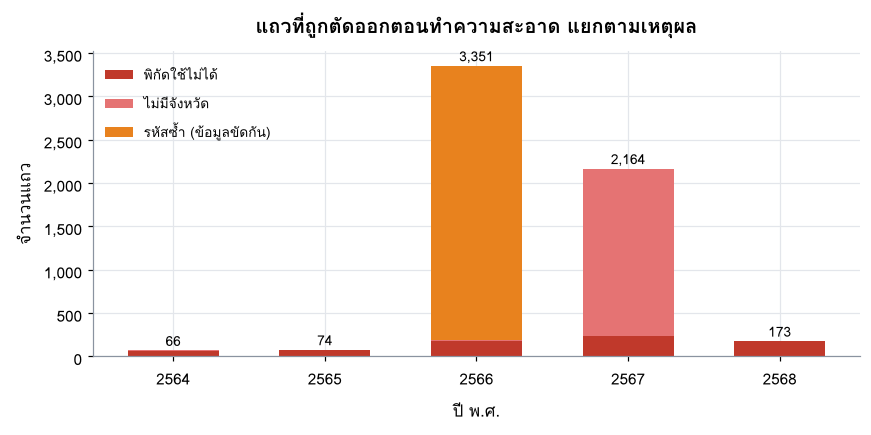

In [8]:
for y, d in raw.items():
    # แปลงพิกัดเป็นตัวเลข
    lat = pd.to_numeric(d["LATITUDE"], errors="coerce"); lon = pd.to_numeric(d["LONGITUDE"], errors="coerce")
    d["lat"], d["lon"] = lat, lon
    # พิกัดต้องอยู่ในกรอบประเทศไทย
    d["coord_ok"] = lat.between(5, 21) & lon.between(97, 106)
    # คอลัมน์ต้นฉบับทั้งหมดของไฟล์ (ไม่รวมคอลัมน์ที่เราเพิ่ม) ใช้เทียบว่าแถวซ้ำเหมือนกันทุกช่องไหม
    KEY = list(d.columns[:list(d.columns).index("be_year")])           # เทียบทุกช่องของไฟล์ต้นฉบับ
    code_ = d["ACC_CODE"].str.strip()
    # จำนวนแถวที่ใช้รหัสเดียวกัน
    size = d.groupby(code_)["source_row"].transform("size")
    # จำนวนแบบของข้อมูลในกลุ่ม (1 = เหมือนกันทุกช่อง)
    n_versions = d[KEY].astype(str).agg("|".join, axis=1).groupby(code_).transform("nunique")
    # แถวแรกของกลุ่ม
    first = d.groupby(code_)["source_row"].transform("min")
    # unique = ไม่ซ้ำ, identical_copy = สำเนา, conflict = ข้อมูลขัดกัน
    d["dup_status"] = np.select([size == 1, n_versions == 1], ["unique", "identical_copy"], "conflict")
    # เก็บแถวที่ไม่ซ้ำ และแถวแรกของกลุ่มสำเนา กลุ่มที่ขัดกันไม่เก็บ
    d["dup_keep"] = (d["dup_status"] == "unique") | ((d["dup_status"] == "identical_copy") & (d["source_row"] == first))

funnel = []
clean_parts = []
REASONS = ["วันที่ผิด", "เวลาผิด", "พิกัดใช้ไม่ได้", "ไม่มีจังหวัด", "รหัสซ้ำ (ข้อมูลขัดกัน)"]
for y, d in raw.items():
    # ติดเหตุผลที่ไม่ผ่าน 1 เหตุผลต่อแถว (เหตุผลแรกที่เจอ) ผ่านทุกข้อ = "ผ่าน"
    d["clean_reason"] = np.select([d["event_date"].isna(), d["seconds"].isna(), ~d["coord_ok"], d["จังหวัด"].str.strip() == "", ~d["dup_keep"]],
                                  REASONS, default="ผ่าน")
    funnel.append(d["clean_reason"].value_counts().rename(y))
    # เก็บแถวที่ผ่าน
    clean_parts.append(d[d["clean_reason"] == "ผ่าน"])
funnel = pd.concat(funnel, axis=1).fillna(0).astype(int)
funnel["รวม"] = funnel.sum(axis=1)
display(funnel)
# รวมทุกปี = ข้อมูลที่ทำความสะอาดแล้ว
clean = pd.concat(clean_parts, ignore_index=True)

# กราฟแท่งซ้อน: จำนวนแถวที่ถูกตัดออก แยกเหตุผล
drop = funnel.drop(index="ผ่าน")[YEARS_BE]
fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = np.zeros(len(YEARS_BE))
for reason, color in zip(drop.index, [RED, "#E57373", AMBER, GREY, NAVY]):
    ax.bar([str(y) for y in YEARS_BE], drop.loc[reason], bottom=bottom, color=color, label=reason, width=.6)
    bottom += drop.loc[reason].to_numpy()
for i, t in enumerate(bottom):
    ax.annotate(f"{int(t):,}", (i, t), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
commas(ax); ax.set_title("แถวที่ถูกตัดออกตอนทำความสะอาด แยกตามเหตุผล"); ax.set_xlabel("ปี พ.ศ."); ax.set_ylabel("จำนวนแถว")
ax.legend(fontsize=9, loc="upper left")
plt.show()
print(f"ข้อมูลดิบ {sum(len(d) for d in raw.values()):,} แถว → ผ่านการทำความสะอาด {len(clean):,} แถว")

**ตรวจเทียบกับ pipeline จริง:** ชุดแถวที่ผ่านการทำความสะอาด วันที่ และช่วงเวลา ต้องตรงกับข้อมูลที่โน้ตบุ๊ก 18 ใช้ (`event_linkage_audit.csv.gz`)

In [9]:
# อ่านผลของ pipeline จริง (โน้ตบุ๊ก 18) มาตรวจเทียบ
audit = pd.read_csv(LINK / "event_linkage_audit.csv.gz", low_memory=False,
                    usecols=["event_uid", "be_year", "source_row", "event_date", "time_block", "status_50m", "segment_status",
                             "chosen_distance_m", "source_id", "segment_id_2000m", "lat", "lon"])
# ชุดแถว (ปี, เลขแถว) ของเรา และของ pipeline จริง
ours, theirs = set(zip(clean["be_year"], clean["source_row"])), set(zip(audit["be_year"], audit["source_row"]))
# จับคู่แถวเดียวกัน เพื่อเทียบวันที่และช่วงเวลา
m = clean.merge(audit, on=["be_year", "source_row"], suffixes=("", "_ref"))
print(f"pipeline จริง {len(theirs):,} แถว | ของเรา {len(ours):,} แถว | ตรงกัน {len(ours & theirs):,} แถว")
print(f"วันที่ตรงกัน {(m['event_date'].dt.strftime('%Y-%m-%d') == m['event_date_ref']).mean():.2%} | "
      f"ช่วง 6 ชม. ตรงกัน {(m['time_block'] == m['time_block_ref']).mean():.2%}")

pipeline จริง 106,308 แถว | ของเรา 106,308 แถว | ตรงกัน 106,308 แถว
วันที่ตรงกัน 100.00% | ช่วง 6 ชม. ตรงกัน 100.00%


---
# 4 · EDA — สำรวจข้อมูล

ใช้ข้อมูลที่ทำความสะอาดแล้ว 106,308 รายการ (2564–2568) สิ่งที่เห็นในส่วนนี้คือที่มาของ **ตัวแปรที่ใส่ในโมเดล** (ขั้น 5)

In [10]:
# รวมคำที่เขียนต่างกันแต่ความหมายเดียวกัน
CANON = {"ลักษณะการเกิดเหตุ": {"ชนท้าย (ช่องจราจรเดียวกัน)": "ชนท้าย", "ไม่มีรายละเอียด": "ไม่ระบุ"},
         "มูลเหตุสันนิษฐาน": {"ขับรถเร็วเกินอัตราที่กำหนด": "ขับรถเร็วเกินอัตรากำหนด", "มีการตัดหน้าระยะกระชั้นชิด": "คน/รถ/สัตว์ตัดหน้ากระชั้นชิด"}}
# สำเนาข้อมูลสำหรับ EDA
E = clean.copy()
for col in ["จังหวัด", "ลักษณะการเกิดเหตุ", "มูลเหตุสันนิษฐาน", "รถคันที่1", "สภาพอากาศ"]:
    # แก้สระอำที่พิมพ์เป็น นิคหิต + สระอา ให้เป็นตัวเดียวกัน
    E[col] = E[col].str.strip().str.replace("ํา", "ำ", regex=False).replace(CANON.get(col, {}))
for col in ["ผู้เสียชีวิต", "ผู้บาดเจ็บสาหัส", "ผู้บาดเจ็บเล็กน้อย"]:
    # จำนวนผู้เสียชีวิต/บาดเจ็บ เป็นตัวเลข
    E[col] = pd.to_numeric(E[col], errors="coerce").fillna(0)
# เดือน
E["month"] = E["event_date"].dt.month
# วันในสัปดาห์ (0 = จันทร์)
E["dow"] = E["event_date"].dt.dayofweek
# เดือน×100 + วัน เช่น 413 = 13 เม.ย.
md_ = E["event_date"].dt.month * 100 + E["event_date"].dt.day
# สงกรานต์ 11–17 เม.ย., ปีใหม่ 29 ธ.ค.–4 ม.ค. (7 วันอันตราย)
E["festival"] = np.select([md_.between(411, 417), (md_ >= 1229) | (md_ <= 104)], ["สงกรานต์", "ปีใหม่"], "วันปกติ")
print(f"{len(E):,} รายการ · ผู้เสียชีวิต {int(E['ผู้เสียชีวิต'].sum()):,} ราย · บาดเจ็บสาหัส {int(E['ผู้บาดเจ็บสาหัส'].sum()):,} ราย")

106,308 รายการ · ผู้เสียชีวิต 13,355 ราย · บาดเจ็บสาหัส 13,632 ราย


### 4.1 แนวโน้มรายปีและรายเดือน

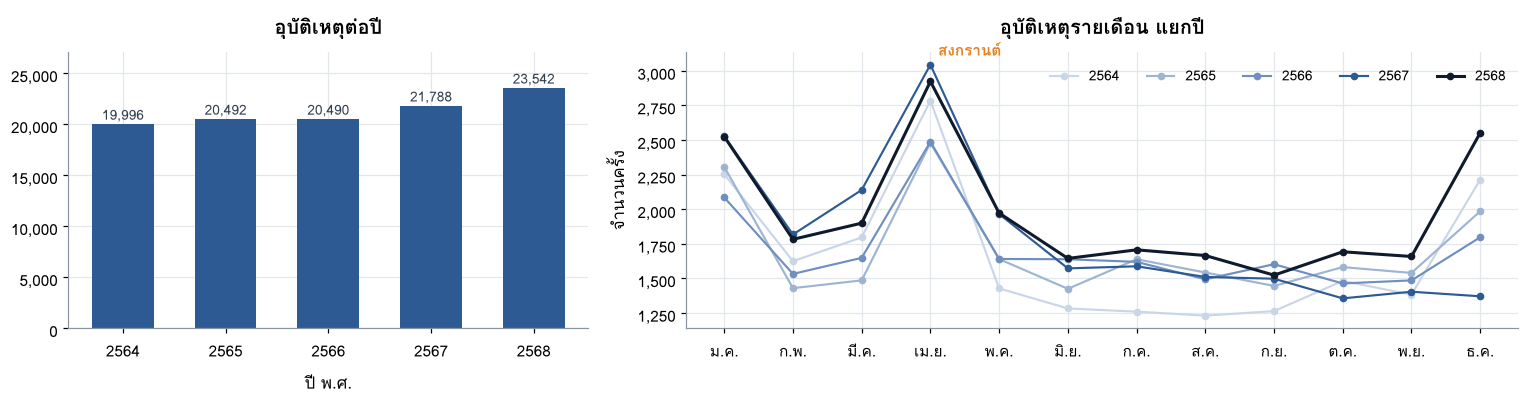

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
# จำนวนอุบัติเหตุและผู้เสียชีวิตต่อปี
yr = E.groupby("be_year").agg(acc=("source_row", "size"), dead=("ผู้เสียชีวิต", "sum"))
ax[0].bar(yr.index.astype(str), yr["acc"], color=BLUE, width=.6); label_bars(ax[0]); commas(ax[0])
ax[0].set_title("อุบัติเหตุต่อปี"); ax[0].set_xlabel("ปี พ.ศ."); ax[0].set_ylim(0, yr["acc"].max() * 1.15)
# ตาราง เดือน × ปี
mon = E.groupby(["be_year", "month"]).size().unstack(0)
for y, c in zip(mon.columns, ["#C9D6E8", "#9DB4D3", "#6F8FBE", BLUE, NAVY]):
    ax[1].plot(range(1, 13), mon[y], marker="o", ms=4, color=c, label=str(y), lw=2 if y == mon.columns[-1] else 1.4)
ax[1].set_xticks(range(1, 13), TH_MONTH); commas(ax[1]); ax[1].legend(ncol=5, fontsize=9, loc="upper right")
ax[1].set_title("อุบัติเหตุรายเดือน แยกปี"); ax[1].set_ylabel("จำนวนครั้ง")
ax[1].annotate("สงกรานต์", (4, mon.loc[4].max()), xytext=(5, 6), textcoords="offset points", color=AMBER, fontweight="bold")
plt.tight_layout(); plt.show()

**สิ่งที่เห็น:** จำนวนเพิ่มขึ้นเล็กน้อยทุกปี เดือน **เมษายน (สงกรานต์)** และ **ธ.ค.–ม.ค. (ปีใหม่)** สูงชัดเจนทุกปี → ใส่ **ตัวแปรเทศกาล** และ **ฤดู** เข้าโมเดล

### 4.2 ช่วงเวลาของวัน และวันในสัปดาห์

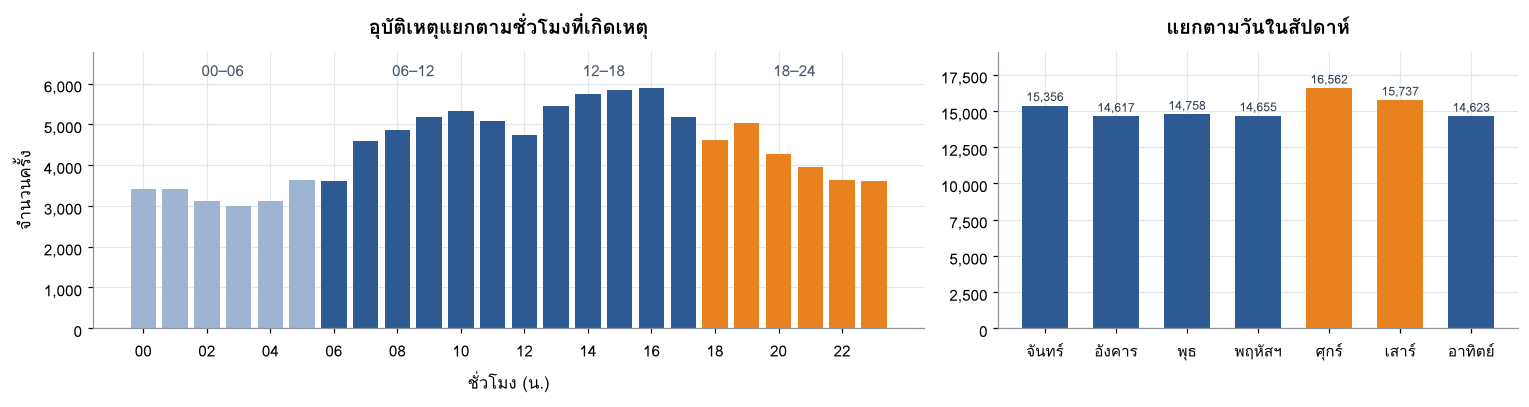

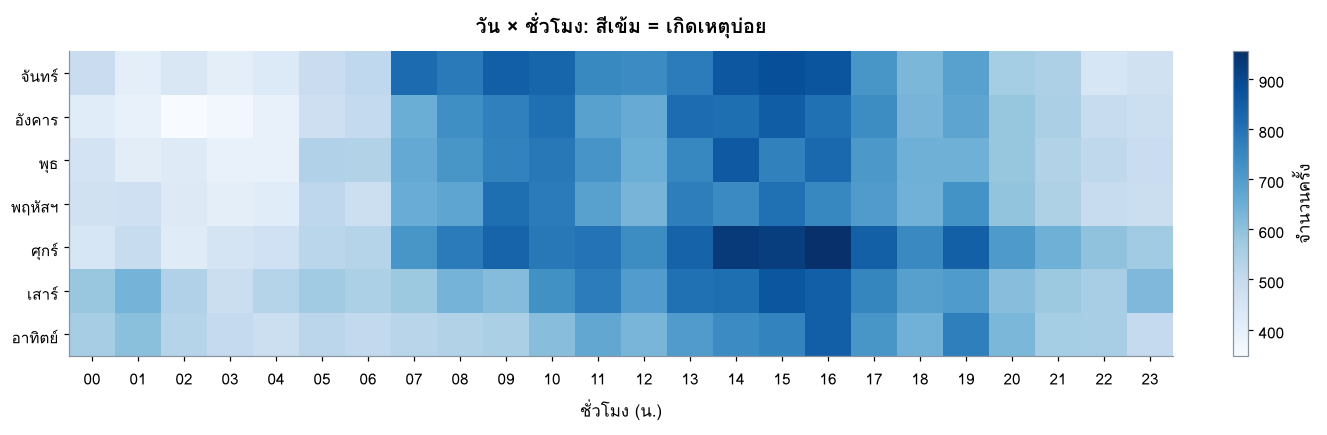

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
# จำนวนต่อชั่วโมง 0–23
hr = E.groupby("hour").size().reindex(range(24), fill_value=0)
cols_ = [LIGHT if h < 6 else BLUE if h < 18 else AMBER for h in range(24)]
ax[0].bar(range(24), hr, color=cols_, width=.8); commas(ax[0])
for x0, lab in [(2.5, "00–06"), (8.5, "06–12"), (14.5, "12–18"), (20.5, "18–24")]:
    ax[0].text(x0, hr.max() * 1.05, lab, ha="center", fontsize=10, color="#4A5566")
ax[0].set_ylim(0, hr.max() * 1.15); ax[0].set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax[0].set_title("อุบัติเหตุแยกตามชั่วโมงที่เกิดเหตุ"); ax[0].set_xlabel("ชั่วโมง (น.)"); ax[0].set_ylabel("จำนวนครั้ง")
# จำนวนต่อวันในสัปดาห์
dw = E.groupby("dow").size().reindex(range(7))
ax[1].bar(TH_DOW, dw, color=[BLUE] * 4 + [AMBER, AMBER, BLUE], width=.65); commas(ax[1]); label_bars(ax[1], size=8)
ax[1].set_ylim(0, dw.max() * 1.15); ax[1].set_title("แยกตามวันในสัปดาห์")
plt.tight_layout(); plt.show()

# ตาราง วัน × ชั่วโมง สำหรับ heatmap
heat = E.groupby(["dow", "hour"]).size().unstack().reindex(index=range(7), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(14, 3.6))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), TH_DOW); ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)]); ax.grid(False)
ax.set_title("วัน × ชั่วโมง: สีเข้ม = เกิดเหตุบ่อย"); ax.set_xlabel("ชั่วโมง (น.)")
plt.colorbar(im, ax=ax, label="จำนวนครั้ง", fraction=.025)
plt.show()

**สิ่งที่เห็น:** ช่วงกลางวันถึงเย็น (12–18 น.) เกิดบ่อยที่สุด วันศุกร์และเสาร์สูงที่สุดในสัปดาห์ และบ่ายวันศุกร์เข้มที่สุดในตาราง วัน × ชั่วโมง (ช่วงคนเริ่มเดินทางวันหยุด) → ใส่ **ช่วงเวลา (time_block)**, **วันในสัปดาห์** และ **วันหยุดสุดสัปดาห์** เป็นตัวแปร
> 💡 นี่คือเหตุผลที่เว็บทำนาย **ราย 6 ชม.** ไม่ใช่แค่รายวัน เพราะเวลาออกเดินทางเปลี่ยนความเสี่ยงได้จริง

### 4.3 เทศกาล

สงกรานต์มีอุบัติเหตุต่อวันมากกว่าวันปกติ 3.6 เท่า


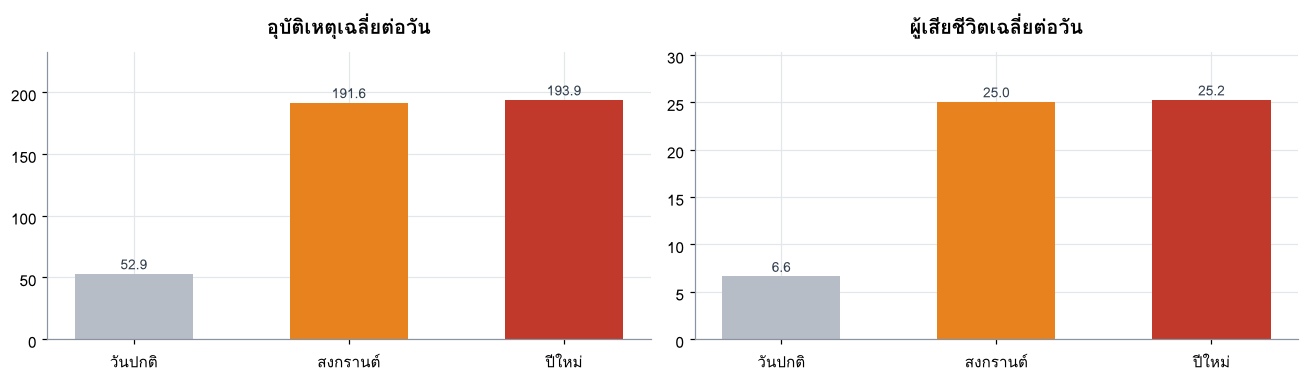

In [13]:
# ทุกวันใน 5 ปี ใช้นับจำนวนวันของแต่ละช่วง (เพื่อหาค่าเฉลี่ยต่อวัน)
days = pd.Series(pd.date_range("2021-01-01", "2025-12-31"))
dmd = days.dt.month * 100 + days.dt.day
n_days = pd.Series(np.select([dmd.between(411, 417), (dmd >= 1229) | (dmd <= 104)], ["สงกรานต์", "ปีใหม่"], "วันปกติ")).value_counts()
# จำนวนรวมแต่ละช่วง แล้วหารด้วยจำนวนวัน = ค่าเฉลี่ยต่อวัน
fest = E.groupby("festival").agg(acc=("source_row", "size"), dead=("ผู้เสียชีวิต", "sum"))
fest = fest.div(n_days, axis=0).reindex(["วันปกติ", "สงกรานต์", "ปีใหม่"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, col, title in [(ax[0], "acc", "อุบัติเหตุเฉลี่ยต่อวัน"), (ax[1], "dead", "ผู้เสียชีวิตเฉลี่ยต่อวัน")]:
    a.bar(fest.index, fest[col], color=[GREY, AMBER, RED], width=.55); label_bars(a, "{:,.1f}")
    a.set_ylim(0, fest[col].max() * 1.2); a.set_title(title)
plt.tight_layout(); plt.show()
print(f"สงกรานต์มีอุบัติเหตุต่อวันมากกว่าวันปกติ {fest.loc['สงกรานต์', 'acc'] / fest.loc['วันปกติ', 'acc']:.1f} เท่า")

### 4.4 พื้นที่: จังหวัด และตำแหน่งบนแผนที่

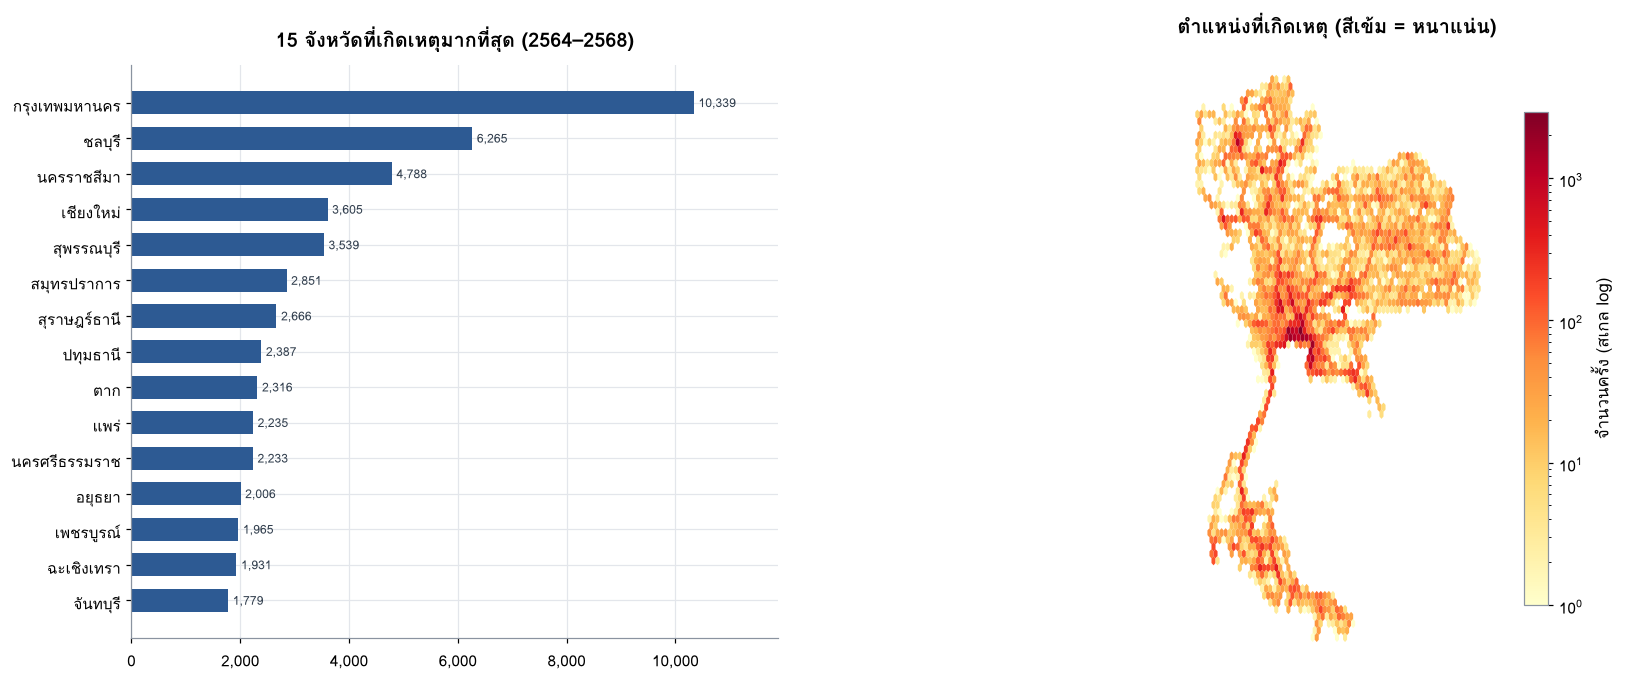

In [14]:
fig = plt.figure(figsize=(14, 6.2))
ax1 = fig.add_axes([0.04, 0.08, 0.42, 0.84])
# 15 จังหวัดที่เกิดเหตุมากที่สุด
top = E["จังหวัด"].value_counts().head(15)[::-1]
ax1.barh(top.index, top.values, color=BLUE, height=.65); label_bars(ax1, horizontal=True, size=8); commas(ax1, "x")
ax1.set_title("15 จังหวัดที่เกิดเหตุมากที่สุด (2564–2568)"); ax1.set_xlim(0, top.max() * 1.15)
ax2 = fig.add_axes([0.56, 0.04, 0.40, 0.9])
ok = audit["lat"].between(5, 21) & audit["lon"].between(97, 106)
# แผนที่ความหนาแน่นแบบหกเหลี่ยม (สเกล log)
hb = ax2.hexbin(audit.loc[ok, "lon"], audit.loc[ok, "lat"], gridsize=70, bins="log", cmap="YlOrRd", mincnt=1, linewidths=0)
ax2.set_aspect(1.03); ax2.set_title("ตำแหน่งที่เกิดเหตุ (สีเข้ม = หนาแน่น)"); ax2.grid(False)
ax2.set_xticks([]); ax2.set_yticks([])
for s in ax2.spines.values(): s.set_visible(False)
plt.colorbar(hb, ax=ax2, label="จำนวนครั้ง (สเกล log)", fraction=.04)
plt.show()

**สิ่งที่เห็น:** อุบัติเหตุกระจุกตามแนวทางหลวงสายหลักและรอบเมืองใหญ่ → ใส่ **ตำแหน่ง** และ **เลขสายทาง** ของช่วงถนนเป็นตัวแปร

### 4.5 ลักษณะ สาเหตุ ยานพาหนะ และสภาพอากาศ (ไม่ได้ใช้เป็นตัวแปร แต่ช่วยให้เข้าใจปัญหา)

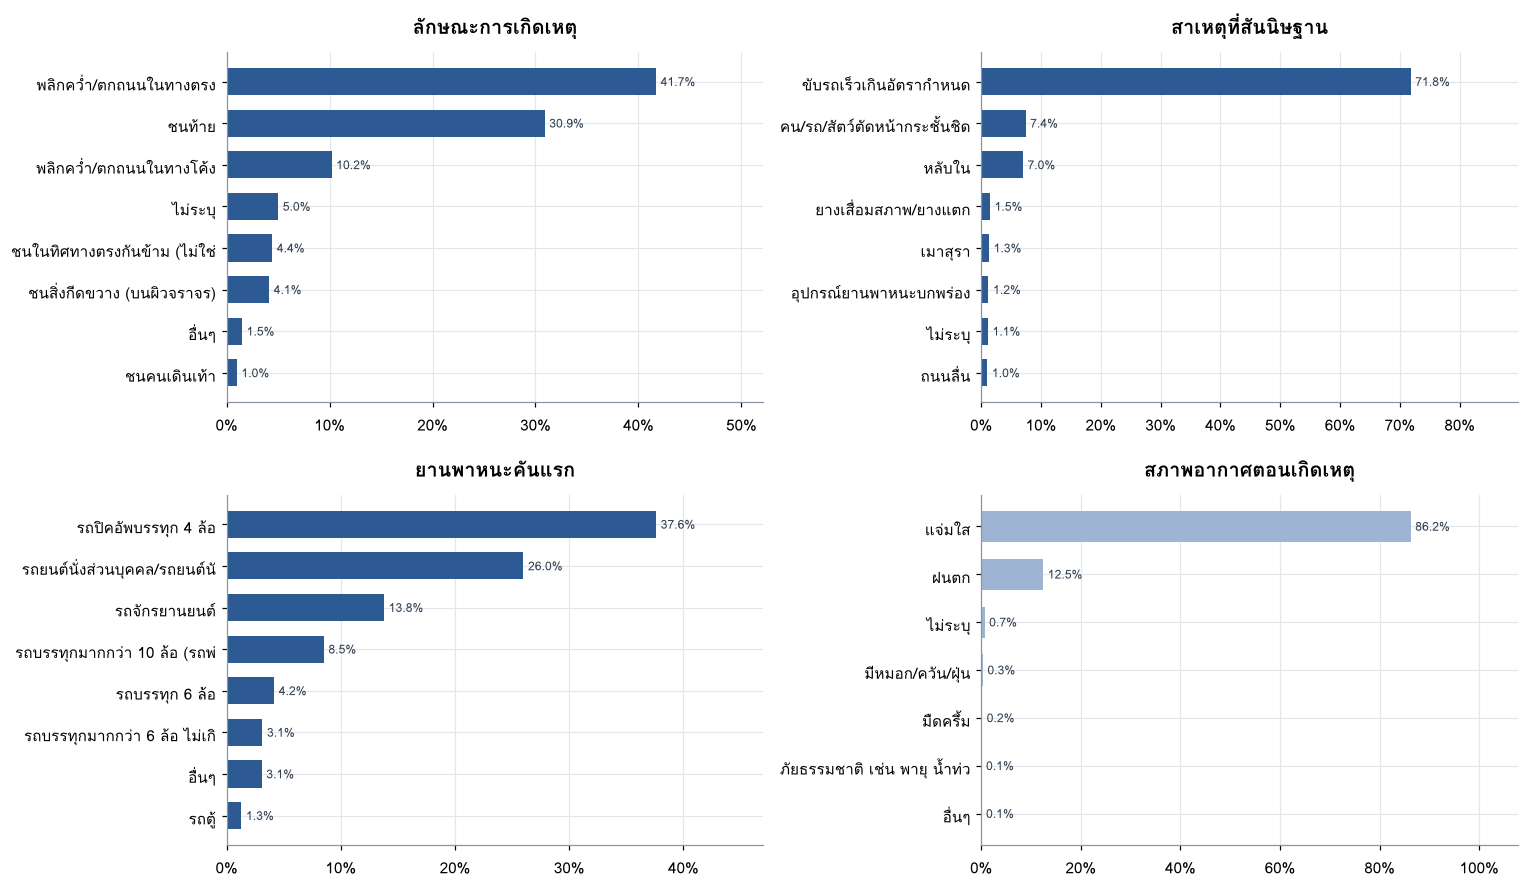

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.2))
for a, col, title in [(axes[0, 0], "ลักษณะการเกิดเหตุ", "ลักษณะการเกิดเหตุ"), (axes[0, 1], "มูลเหตุสันนิษฐาน", "สาเหตุที่สันนิษฐาน"),
                      (axes[1, 0], "รถคันที่1", "ยานพาหนะคันแรก"), (axes[1, 1], "สภาพอากาศ", "สภาพอากาศตอนเกิดเหตุ")]:
    # นับแต่ละค่า แล้วแสดง 8 อันดับแรกเป็นสัดส่วน
    v = E[col].replace("", "ไม่ระบุ").value_counts()
    v = v.head(8)[::-1] / len(E)
    a.barh([t[:28] for t in v.index], v.values, color=BLUE if col != "สภาพอากาศ" else LIGHT, height=.65)
    label_bars(a, "{:.1%}", horizontal=True, size=8); a.xaxis.set_major_formatter(PercentFormatter(1, 0))
    a.set_xlim(0, v.max() * 1.25); a.set_title(title)
plt.tight_layout(); plt.show()

**สิ่งที่เห็น:** สาเหตุอันดับต้นคือขับเร็วเกินกำหนดและหลับใน ข้อมูลกลุ่มนี้ **ไม่ได้ใช้เป็นตัวแปร** เพราะรู้หลังเกิดเหตุแล้ว แต่ใช้แสดง "ส่วนใหญ่เกิดจาก…" ของแต่ละจุดบนหน้าเว็บ

### 4.6 อุบัติเหตุกระจุกตัวแค่ไหน (เทียบรายช่วงถนน)
ใช้รายการที่จับคู่ถนนได้ 98,207 รายการ (ขั้น 5) นับต่อช่วงถนนตลอด 5 ปี

ช่วงถนนที่ไม่เคยเกิดเหตุเลยใน 5 ปี: 37.8%


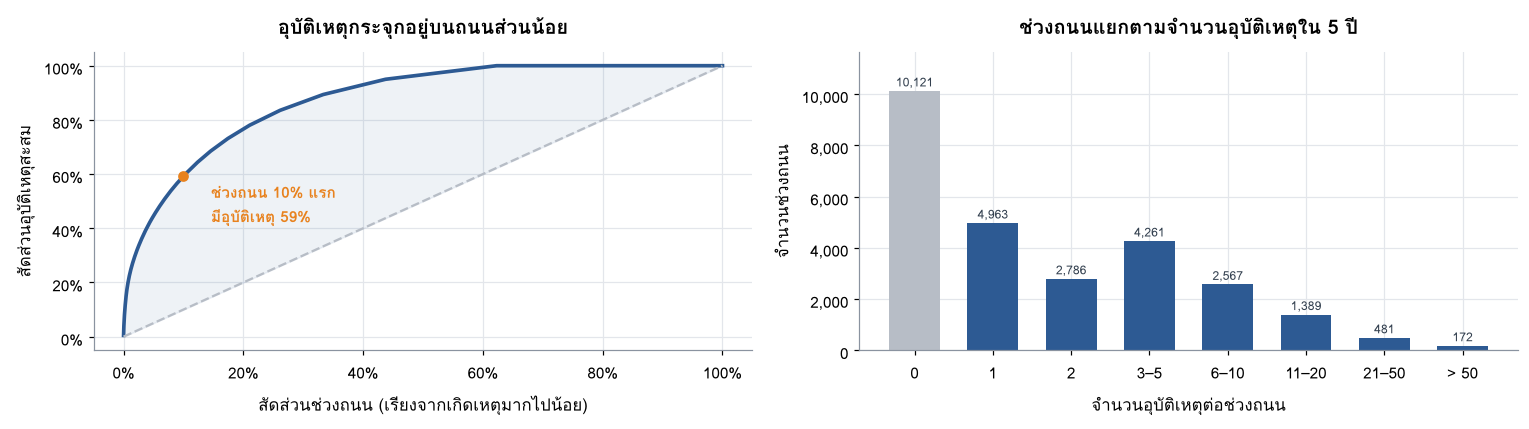

In [16]:
# ตารางช่วงถนนทั้ง 26,740 ช่วง (ผลของโน้ตบุ๊ก 19)
uni = pd.read_csv(PREP / "universe_segments.csv", dtype={"route_code": str})
# รายการอุบัติเหตุที่ใช้ฝึก 98,207 รายการ
sel = pd.read_csv(PREP / "selected_events.csv.gz")
# จำนวนอุบัติเหตุต่อช่วงถนน (ช่วงที่ไม่เคยเกิด = 0) เรียงจากมากไปน้อย
per_seg = sel["segment_id_2000m"].value_counts().reindex(uni["segment_id"], fill_value=0).sort_values(ascending=False).to_numpy()
# สัดส่วนอุบัติเหตุสะสม (เส้นโค้ง Lorenz)
cum = np.cumsum(per_seg) / per_seg.sum()
share = np.arange(1, len(per_seg) + 1) / len(per_seg)
# สัดส่วนอุบัติเหตุที่อยู่บนช่วงถนน 10% แรก
top10 = cum[int(len(per_seg) * .1) - 1]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(share, cum, color=BLUE, lw=2.4); ax[0].plot([0, 1], [0, 1], "--", color=GREY)
ax[0].fill_between(share, cum, share, color=BLUE, alpha=.08)
ax[0].scatter([.1], [top10], color=AMBER, zorder=3); ax[0].annotate(f"ช่วงถนน 10% แรก\nมีอุบัติเหตุ {top10:.0%}", (.1, top10), xytext=(18, -30), textcoords="offset points", color=AMBER, fontweight="bold")
ax[0].xaxis.set_major_formatter(PercentFormatter(1, 0)); ax[0].yaxis.set_major_formatter(PercentFormatter(1, 0))
ax[0].set_xlabel("สัดส่วนช่วงถนน (เรียงจากเกิดเหตุมากไปน้อย)"); ax[0].set_ylabel("สัดส่วนอุบัติเหตุสะสม"); ax[0].set_title("อุบัติเหตุกระจุกอยู่บนถนนส่วนน้อย")
bins = [0, 1, 2, 3, 6, 11, 21, 51, per_seg.max() + 1]
labels = ["0", "1", "2", "3–5", "6–10", "11–20", "21–50", "> 50"]
cnt = pd.cut(per_seg, bins, right=False, labels=labels).value_counts().reindex(labels)
ax[1].bar(labels, cnt.values, color=[GREY] + [BLUE] * 7, width=.65); label_bars(ax[1], size=8); commas(ax[1])
ax[1].set_ylim(0, cnt.max() * 1.15); ax[1].set_title("ช่วงถนนแยกตามจำนวนอุบัติเหตุใน 5 ปี"); ax[1].set_xlabel("จำนวนอุบัติเหตุต่อช่วงถนน"); ax[1].set_ylabel("จำนวนช่วงถนน")
plt.tight_layout(); plt.show()
print(f"ช่วงถนนที่ไม่เคยเกิดเหตุเลยใน 5 ปี: {(per_seg == 0).mean():.1%}")

> 💡 **ข้อสรุปสำคัญจาก EDA:** อุบัติเหตุ **ไม่ได้กระจายเท่า ๆ กัน** ช่วงถนนส่วนน้อยมีเหตุส่วนใหญ่ และขึ้นกับ **เวลา** (ช่วงของวัน วันหยุด เทศกาล ฤดู) ชัดเจน จึงเหมาะกับการทำนายราย **ช่วงถนน × เวลา** และส่วนใหญ่ของช่องเป็น 0 จึงต้องใช้โมเดล **Poisson**

---
# 5 · Data Preparation — เตรียมข้อมูลให้โมเดล

### 5.1 ช่วงถนนที่ใช้ (universe)
- ใช้ทางหลวงกรมทางหลวงสายมาตรฐาน ตัดเป็น **ช่วงละ 2 กม.** และเก็บช่วงที่ยาวอย่างน้อย 500 ม.
- **รวมช่วงที่ไม่เคยเกิดเหตุด้วย**

> 💡 ถ้าเก็บเฉพาะถนนที่เคยเกิดเหตุ โมเดลจะไม่เคยเห็นถนนที่ปลอดภัย และจะทายสูงเกินจริงทุกที่

ช่วงถนน 26,740 ช่วง | ทางหลวง 1,440 สาย | ยาวรวม 51,858 กม.


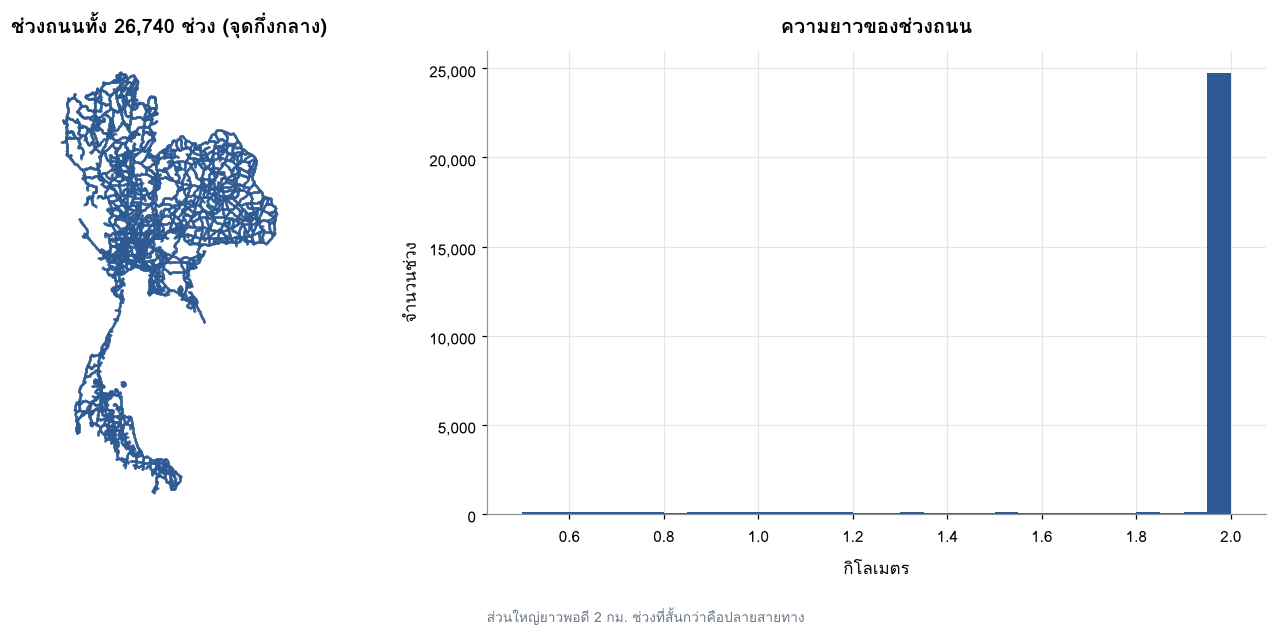

In [17]:
print(f"ช่วงถนน {len(uni):,} ช่วง | ทางหลวง {uni['route_code'].nunique():,} สาย | ยาวรวม {uni['geom_length_m'].sum() / 1000:,.0f} กม.")
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].scatter(uni["geom_mid_lon"], uni["geom_mid_lat"], s=.12, c=BLUE); ax[0].set_aspect(1.03); ax[0].axis("off")
ax[0].set_title("ช่วงถนนทั้ง 26,740 ช่วง (จุดกึ่งกลาง)")
ax[1].hist(uni["geom_length_m"] / 1000, bins=30, color=BLUE); commas(ax[1])
ax[1].set_title("ความยาวของช่วงถนน"); ax[1].set_xlabel("กิโลเมตร"); ax[1].set_ylabel("จำนวนช่วง")
note(ax[1], "ส่วนใหญ่ยาวพอดี 2 กม. ช่วงที่สั้นกว่าคือปลายสายทาง")
plt.tight_layout(); plt.show()

### 5.2 จับคู่จุดเกิดเหตุกับถนน (โน้ตบุ๊ก 18)
จับคู่แต่ละรายการกับเส้นทางที่ใกล้ที่สุดซึ่ง **เลขสายทางตรงกับที่บันทึกไว้**:

| สถานะ | ความหมาย |
|---|---|
| `matched` | ห่างไม่เกิน **50 ม.** และไม่มีถนนอื่นแย่งในระยะใกล้เคียง |
| `too_far` | ใกล้ที่สุดก็ยังเกิน 50 ม. |
| `ambiguous_*` | มีถนนหลายเส้นใกล้พอ ๆ กัน ไม่รู้ว่าเกิดบนเส้นไหน |
| `identity_unresolved` / `route_*` | เลขสายทางไม่ตรงหรือไม่มีในข้อมูลถนน |

> 💡 **ทำไม 50 ม.:** โน้ตบุ๊ก 18 ลอง 25, 50 และ 100 ม. ระยะ 50 ม. เผื่อความคลาดเคลื่อนของ GPS ได้ โดยไม่ไปจับคู่ผิดกับถนนข้างเคียง (การจับคู่ต้องใช้ไฟล์เส้นถนน 233 MB จึงอ่านผลจริงของโน้ตบุ๊ก 18 มาแสดง)

จับคู่ได้ 101,739 จาก 106,308 รายการ (95.7%) · 90% อยู่ในระยะ 16.0 ม.


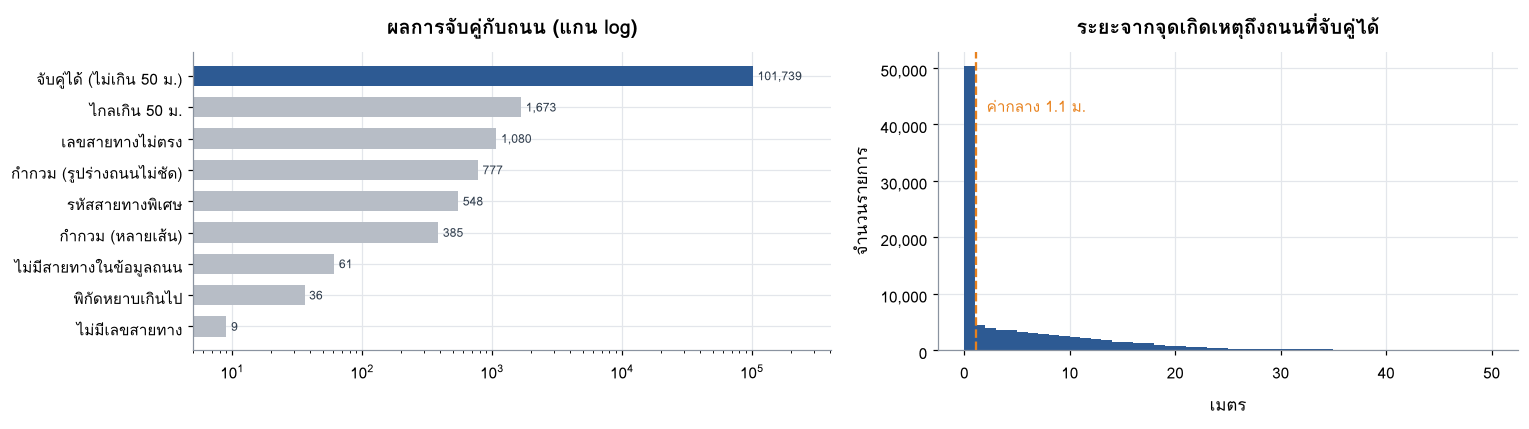

In [18]:
# นับผลการจับคู่ที่ระยะ 50 ม.
st = audit["status_50m"].value_counts()
TH_STATUS = {"matched": "จับคู่ได้ (ไม่เกิน 50 ม.)", "too_far": "ไกลเกิน 50 ม.", "identity_unresolved": "เลขสายทางไม่ตรง",
             "ambiguous_unsafe_geometry": "กำกวม (รูปร่างถนนไม่ชัด)", "route_special_unverified": "รหัสสายทางพิเศษ",
             "ambiguous_multiple": "กำกวม (หลายเส้น)", "route_not_in_snapshot": "ไม่มีสายทางในข้อมูลถนน",
             "low_precision_unsuitable": "พิกัดหยาบเกินไป", "route_missing": "ไม่มีเลขสายทาง"}
# ระยะของรายการที่จับคู่ได้
dist = audit.loc[audit["status_50m"] == "matched", "chosen_distance_m"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.1, 1]})
s2 = st.rename(TH_STATUS)[::-1]
ax[0].barh(s2.index, s2.values, color=[GREY] * (len(s2) - 1) + [BLUE], height=.65); label_bars(ax[0], horizontal=True, size=8)
ax[0].set_xscale("log"); ax[0].set_title("ผลการจับคู่กับถนน (แกน log)"); ax[0].set_xlim(5, st.max() * 4)
ax[1].hist(dist, bins=np.arange(0, 51, 1), color=BLUE); commas(ax[1])
ax[1].set_title("ระยะจากจุดเกิดเหตุถึงถนนที่จับคู่ได้"); ax[1].set_xlabel("เมตร"); ax[1].set_ylabel("จำนวนรายการ")
ax[1].axvline(dist.median(), color=AMBER, ls="--"); ax[1].text(dist.median() + 1, ax[1].get_ylim()[1] * .8, f"ค่ากลาง {dist.median():.1f} ม.", color=AMBER)
plt.tight_layout(); plt.show()
print(f"จับคู่ได้ {st['matched']:,} จาก {len(audit):,} รายการ ({st['matched'] / len(audit):.1%}) · 90% อยู่ในระยะ {dist.quantile(.9):.1f} ม.")

### 5.3 เลือกรายการที่ใช้ฝึก (`select_events` · โน้ตบุ๊ก 19)
ต้องจับคู่ได้ภายใน 50 ม. **และ** ช่วงถนนอยู่ในชุด 26,740 ช่วง (ไม่ใช่ถนนกรมทางหลวงชนบท ทางพิเศษ หรือช่วงที่สั้นเกิน)

รายการที่ไม่ผ่าน **ไม่ถูกนับเป็นศูนย์** แต่เก็บไว้พร้อมเหตุผล

ตรงกับ selected_events ของโน้ตบุ๊ก 19: True


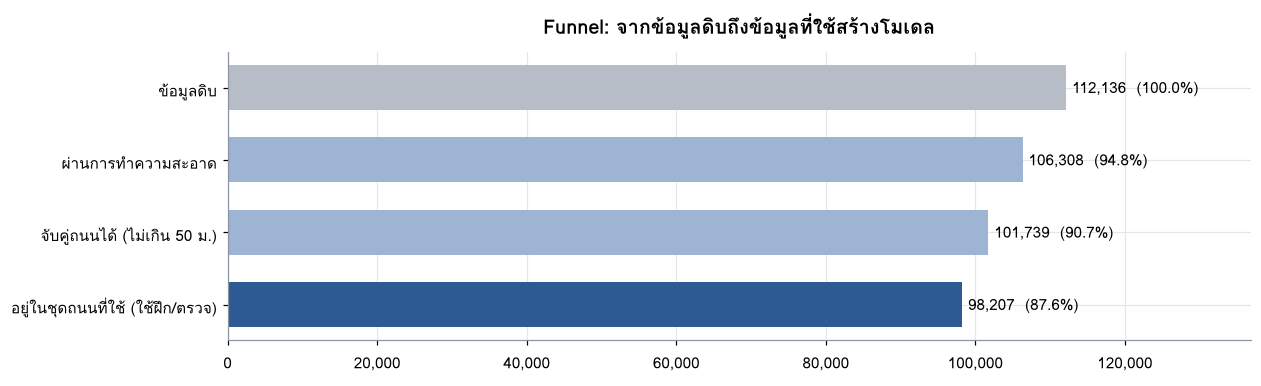

In [19]:
# ชุดรหัสช่วงถนนที่ใช้
in_uni = set(uni["segment_id"])
# เงื่อนไขเลือก: จับคู่ได้ใน 50 ม. + ได้ช่วงถนน + ช่วงถนนอยู่ในชุดที่ใช้
ok_sel = (audit["status_50m"] == "matched") & (audit["segment_status"] == "assigned") & audit["segment_id_2000m"].isin(in_uni)
print("ตรงกับ selected_events ของโน้ตบุ๊ก 19:", set(audit.loc[ok_sel, "event_uid"]) == set(sel["event_uid"]))
steps = pd.Series({"ข้อมูลดิบ": sum(len(d) for d in raw.values()), "ผ่านการทำความสะอาด": len(audit),
                   "จับคู่ถนนได้ (ไม่เกิน 50 ม.)": int((audit["status_50m"] == "matched").sum()), "อยู่ในชุดถนนที่ใช้ (ใช้ฝึก/ตรวจ)": int(ok_sel.sum())})
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.barh(steps.index[::-1], steps.values[::-1], color=[BLUE, LIGHT, LIGHT, GREY], height=.62)
for i, (k, v) in enumerate(steps[::-1].items()):
    ax.text(v + 800, i, f"{v:,}  ({v / steps.iloc[0]:.1%})", va="center", fontsize=10)
ax.set_xlim(0, steps.max() * 1.22); commas(ax, "x"); ax.set_title("Funnel: จากข้อมูลดิบถึงข้อมูลที่ใช้สร้างโมเดล")
plt.show()

### 5.4 สร้างตารางเป้าหมาย (label)

> **y = จำนวนอุบัติเหตุที่ถูกบันทึกและจับคู่ได้ บนช่วงถนน *s* ในวัน *d* ช่วงเวลา *b***

1 แถว = 1 ช่วงถนน × 1 วัน × 1 ช่วง 6 ชม. **รวมช่องที่ไม่เกิดเหตุ (y = 0)** ด้วย

ช่องทั้งหมด 26,740 × 1,826 วัน × 4 ช่วง = 195,308,960 ช่อง
ช่องที่เกิดเหตุ 96,765 ช่อง → เป็นศูนย์ 99.950%
นับจาก selected_events แล้วได้ตรงกับ counts_6h.csv.gz ทุกช่อง: True


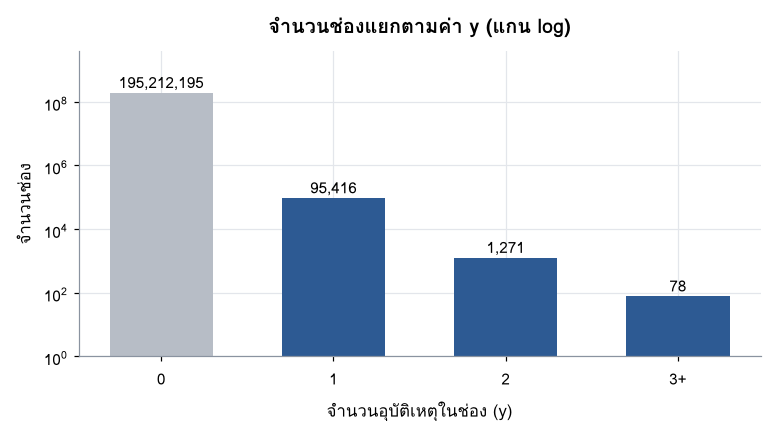

In [20]:
# ตารางเป้าหมายราย 6 ชม. (เฉพาะช่องที่ y > 0)
c6 = pd.read_csv(PREP / "counts_6h.csv.gz")               # เก็บเฉพาะช่องที่ y > 0 ช่องที่ไม่มีในไฟล์คือ 0
# จำนวนวันทั้งหมด 2564–2568 = 1,826 วัน
n_days_all = (pd.Timestamp("2025-12-31") - pd.Timestamp("2021-01-01")).days + 1
# จำนวนช่องทั้งหมด = ช่วงถนน × วัน × 4 ช่วงเวลา
cells = len(uni) * n_days_all * 4
# นับใหม่จากรายการที่เลือก เพื่อตรวจว่าได้ตรงกับไฟล์
recount = sel.groupby(["segment_id_2000m", "event_date", "time_block"]).size().rename("y").reset_index()
chk = recount.merge(c6, left_on=["segment_id_2000m", "event_date", "time_block"], right_on=["segment_id", "target_date", "time_block"], how="outer")
print(f"ช่องทั้งหมด {len(uni):,} × {n_days_all:,} วัน × 4 ช่วง = {cells:,} ช่อง")
print(f"ช่องที่เกิดเหตุ {len(c6):,} ช่อง → เป็นศูนย์ {1 - len(c6) / cells:.3%}")
print("นับจาก selected_events แล้วได้ตรงกับ counts_6h.csv.gz ทุกช่อง:", bool((chk["y"] == chk["y_count"]).all()))

vc = c6["y_count"].value_counts().sort_index()
# จำนวนช่องแยกตามค่า y
dist_y = pd.Series({"0": cells - len(c6), "1": vc.get(1, 0), "2": vc.get(2, 0), "3+": vc[vc.index >= 3].sum()})
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(dist_y.index, dist_y.values, color=[GREY, BLUE, BLUE, BLUE], width=.6); ax.set_yscale("log")
for i, v in enumerate(dist_y.values):
    ax.text(i, v * 1.4, f"{v:,}", ha="center", fontsize=10)
ax.set_title("จำนวนช่องแยกตามค่า y (แกน log)"); ax.set_xlabel("จำนวนอุบัติเหตุในช่อง (y)"); ax.set_ylabel("จำนวนช่อง")
ax.set_ylim(1, dist_y.max() * 20)
plt.show()

> 💡 ข้อมูลเป็นศูนย์ **99.95%** ถ้าใช้ accuracy หรือ RMSE ทาย 0 ทุกช่องก็ได้คะแนนดีแล้ว จึงใช้ **Poisson** ทั้งตอนฝึก (loss) และตอนวัดผล (deviance)

### 5.5 สร้างตัวแปร (features)

| กลุ่ม | ตัวแปร | ที่มาจาก EDA |
|---|---|---|
| **ถนน** (11) | `route_code`, ตำแหน่งกึ่งกลาง (x, y, lon, lat), ความยาว, log ความยาว, ทิศ (sin, cos), ความตรง, ความโค้งต่อ กม. | 4.4, 4.6 |
| **วัน** (22) | วันในสัปดาห์, เดือน, วันที่, วันหยุดสุดสัปดาห์, `doy_sin/cos`, สงกรานต์และปีใหม่ (ก่อน 1–3 / 4–7 วัน, ระหว่าง, หลัง 1–3 / 4–7 วัน, ระยะห่าง), ฤดูร้อน/ฝน/หนาว, วันหยุดธนาคาร | 4.1–4.3 |
| **ช่วงเวลา** (1) | `time_block` (เฉพาะโมเดลราย 6 ชม.) | 4.2 |
| **บริบท** (ทางเลือก) | ฝนและอุณหภูมิที่พยากรณ์ล่วงหน้า 2 วัน, AADT ปีก่อน | — |

จำนวนตัวแปรของโมเดลหลัก (ราย 6 ชม.): 34
ตัวอย่างตัวแปรของวัน ช่วงสงกรานต์ 2566:


,target_date,day_of_week,fest_songkran_dist,fest_songkran_pre_1_3,fest_songkran_in,fest_songkran_post_1_3,season_hot,bank_holiday_asof
827,2023-04-08,5.0,-5.0,0.0,0.0,0.0,1.0,0.0
828,2023-04-09,6.0,-4.0,0.0,0.0,0.0,1.0,0.0
829,2023-04-10,0.0,-3.0,1.0,0.0,0.0,1.0,0.0
830,2023-04-11,1.0,-2.0,1.0,0.0,0.0,1.0,0.0
831,2023-04-12,2.0,-1.0,1.0,0.0,0.0,1.0,0.0
832,2023-04-13,3.0,0.0,0.0,1.0,0.0,1.0,1.0
833,2023-04-14,4.0,0.0,0.0,1.0,0.0,1.0,1.0
834,2023-04-15,5.0,0.0,0.0,1.0,0.0,1.0,0.0
835,2023-04-16,6.0,1.0,0.0,0.0,1.0,1.0,0.0
836,2023-04-17,0.0,2.0,0.0,0.0,1.0,1.0,0.0


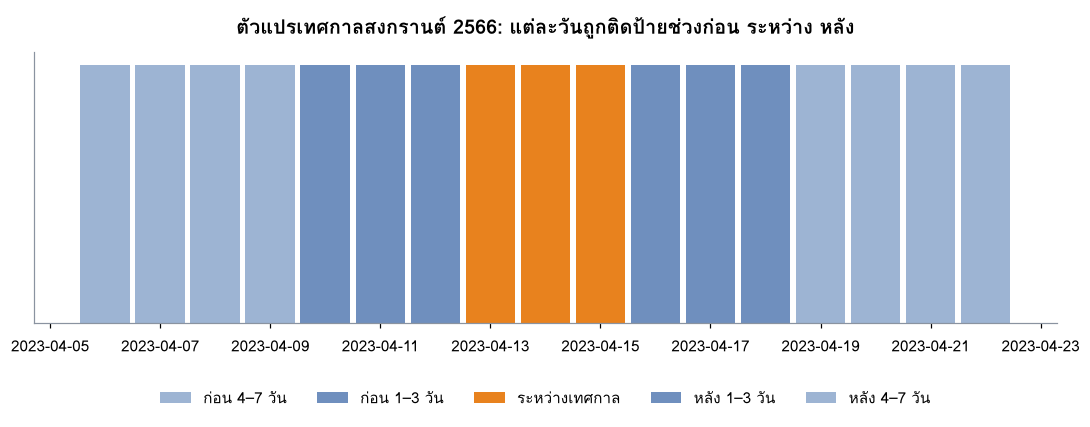

In [21]:
# ตัวแปรของถนน 11 ตัว
STATIC = ["route_code", "geom_mid_x_m", "geom_mid_y_m", "geom_mid_lon", "geom_mid_lat", "geom_length_m", "geom_log_length_m",
          "geom_bearing_sin", "geom_bearing_cos", "geom_straightness", "geom_turning_rad_per_km"]
# ค่าตั้งของตัวแปร (ชื่อตัวแปรวัน และคอลัมน์ต้องห้าม)
CTX = json.loads((PREP / "context_settings.json").read_text("utf-8"))
# ตัวแปรของวัน 22 ตัว
DATE_COLS = CTX["date_feature_columns"]
# ตารางตัวแปรของวัน 1 แถวต่อ 1 วัน
dates = pd.read_csv(PREP / "date_features.csv")
# ตัวแปรของโมเดลหลักราย 6 ชม. = 11 + 22 + 1 = 34 ตัว
FEATURES_6H = STATIC + DATE_COLS + ["time_block"]
print("จำนวนตัวแปรของโมเดลหลัก (ราย 6 ชม.):", len(FEATURES_6H))
print("ตัวอย่างตัวแปรของวัน ช่วงสงกรานต์ 2566:")
display(dates.loc[dates["target_date"].between("2023-04-08", "2023-04-18"),
                  ["target_date", "day_of_week", "fest_songkran_dist", "fest_songkran_pre_1_3", "fest_songkran_in", "fest_songkran_post_1_3", "season_hot", "bank_holiday_asof"]])

dd = dates[dates["target_date"].between("2023-03-25", "2023-05-05")]
x = pd.to_datetime(dd["target_date"])
fig, ax = plt.subplots(figsize=(12, 3.2))
for col, lab, c in [("fest_songkran_pre_4_7", "ก่อน 4–7 วัน", LIGHT), ("fest_songkran_pre_1_3", "ก่อน 1–3 วัน", "#6F8FBE"),
                    ("fest_songkran_in", "ระหว่างเทศกาล", AMBER), ("fest_songkran_post_1_3", "หลัง 1–3 วัน", "#6F8FBE"), ("fest_songkran_post_4_7", "หลัง 4–7 วัน", LIGHT)]:
    ax.bar(x[dd[col] == 1], 1, color=c, width=.9, label=lab)
ax.set_yticks([]); ax.set_title("ตัวแปรเทศกาลสงกรานต์ 2566: แต่ละวันถูกติดป้ายช่วงก่อน ระหว่าง หลัง"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.18))
ax.grid(False)
plt.show()

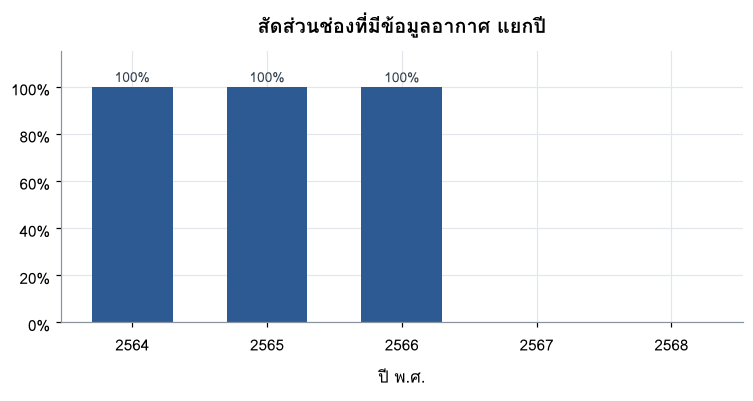

In [22]:
# ตารางข้อมูลอากาศ ใช้ดูว่ามีข้อมูลถึงปีไหน
wx = pd.read_csv(PREP / "weather_context_6h.csv.gz")
cov = wx.assign(ปี=wx["target_date"].str[:4].astype(int) + 543).groupby("ปี")["wx_block_rain_reason"].apply(lambda s: (s == "ok").mean()).reindex(YEARS_BE, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(cov.index.astype(str), cov.values, color=[BLUE if v > .5 else GREY for v in cov.values], width=.6)
label_bars(ax, "{:.0%}"); ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_ylim(0, 1.15)
ax.set_title("สัดส่วนช่องที่มีข้อมูลอากาศ แยกปี"); ax.set_xlabel("ปี พ.ศ.")
plt.show()

**ข้อมูลอากาศมีถึงปี 2566 เท่านั้น** นโยบาย **`routed_context`** จึงใช้โมเดลแบบมีบริบทเฉพาะเมื่อมีข้อมูลอากาศและปริมาณรถครบ ถ้าไม่ครบให้ใช้ **โมเดลหลัก (ถนน + ปฏิทิน)** แทน

การใช้งานจริงบนเว็บ (ปี 2567 ขึ้นไป) จึงใช้โมเดลหลักเกือบทั้งหมด **ขั้น 8 จึงเทรนโมเดลหลัก**

---
# 6 · Split Strategy — แบ่งข้อมูลตามเวลา

- **ไม่สุ่มแบ่ง** เพราะโมเดลจะได้เรียนจากอนาคต แล้วผลจะดีเกินจริง
- ทดสอบย้อนหลัง **4 รอบ** (rolling origin) แต่ละรอบฝึกตั้งแต่ 1 ม.ค. 2564 จนถึงก่อนรอบนั้น แล้ววัดผลกับ 6 เดือนถัดไป
- ข้อมูลฝึกหยุด **30 วันก่อน** วันแรกที่ทำนาย เผื่อว่าอุบัติเหตุบันทึกเข้าระบบช้า
- โมเดลที่ใช้บนเว็บ (`benchmark_2024`) ฝึกถึง 1 ธ.ค. 2566 แล้ว **ล็อกไว้** ปี 2567–2568 ใช้เป็นช่วงตรวจ ปี 2569 เป็นชุดทดสอบ

,รอบ,ข้อมูลฝึกถึง,วัดผลตั้งแต่,วัดผลถึง,จำนวนวันฝึกต่อช่วง
5,2022H1,2021-12-01 18:00:00,2022-01-01,2022-06-30,"[335, 335, 335, 334]"
6,2022H2,2022-05-31 18:00:00,2022-07-01,2022-12-31,"[516, 516, 516, 515]"
7,2023H1,2022-12-01 18:00:00,2023-01-01,2023-06-30,"[700, 700, 700, 699]"
8,2023H2,2023-05-31 18:00:00,2023-07-01,2023-12-31,"[881, 881, 881, 880]"
9,benchmark_2024,2023-12-01 18:00:00,2024-01-01,NaN,"[1065, 1065, 1065, 1064]"


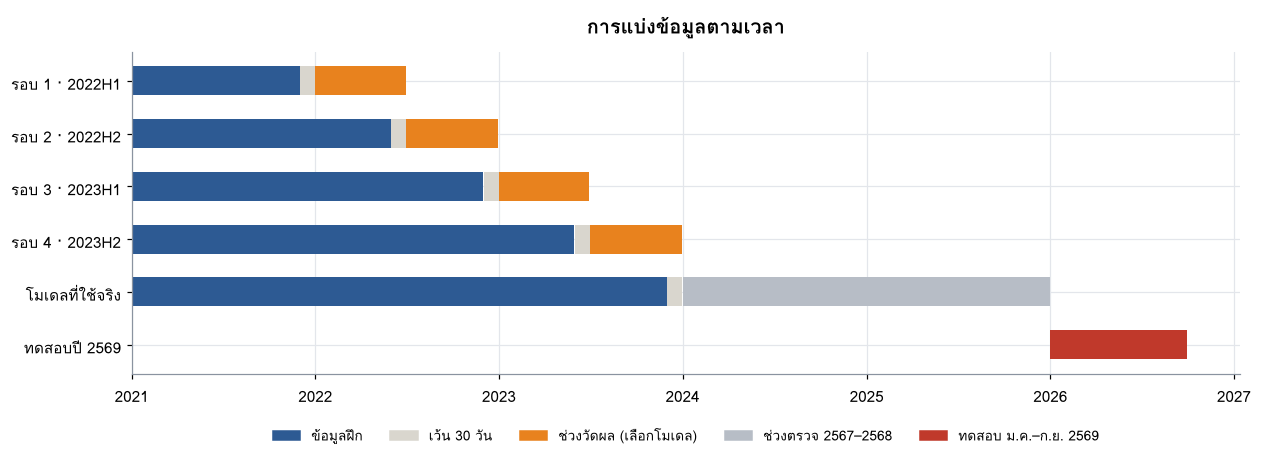

In [23]:
# ตารางรอบการแบ่งข้อมูลจากผลจริงของโน้ตบุ๊ก 20
folds = pd.read_csv(RUN20 / "folds.csv")
f6 = folds[folds["unit"] == "6h"][["fold_id", "train_cutoff_local", "eval_start", "eval_end", "train_dates_per_block"]]
display(f6.rename(columns={"fold_id": "รอบ", "train_cutoff_local": "ข้อมูลฝึกถึง", "eval_start": "วัดผลตั้งแต่", "eval_end": "วัดผลถึง", "train_dates_per_block": "จำนวนวันฝึกต่อช่วง"}))

fig, ax = plt.subplots(figsize=(13, 3.8))
names = list(f6["fold_id"]) + ["ทดสอบ 2569"]
for i, r in enumerate(f6.itertuples()):
    t0, cut = pd.Timestamp("2021-01-01"), pd.Timestamp(r.train_cutoff_local)
    e0 = pd.Timestamp(r.eval_start)
    e1 = pd.Timestamp(r.eval_end) if isinstance(r.eval_end, str) and r.eval_end not in ("None", "") else pd.Timestamp("2025-12-31")
    ax.barh(i, (cut - t0).days, left=t0, color=BLUE, height=.55)
    ax.barh(i, (e0 - cut).days, left=cut, color="#D9D6CE", height=.55)
    ax.barh(i, (e1 - e0).days, left=e0, color=AMBER if r.fold_id != "benchmark_2024" else GREY, height=.55)
ax.barh(len(f6), (pd.Timestamp("2026-09-30") - pd.Timestamp("2026-01-01")).days, left=pd.Timestamp("2026-01-01"), color=RED, height=.55)
ax.set_yticks(range(len(names)), ["รอบ 1 · 2022H1", "รอบ 2 · 2022H2", "รอบ 3 · 2023H1", "รอบ 4 · 2023H2", "โมเดลที่ใช้จริง", "ทดสอบปี 2569"]); ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="ข้อมูลฝึก"), Patch(color="#D9D6CE", label="เว้น 30 วัน"), Patch(color=AMBER, label="ช่วงวัดผล (เลือกโมเดล)"),
                   Patch(color=GREY, label="ช่วงตรวจ 2567–2568"), Patch(color=RED, label="ทดสอบ ม.ค.–ก.ย. 2569")], ncol=5, loc="upper center", bbox_to_anchor=(.5, -.12), fontsize=9)
ax.set_title("การแบ่งข้อมูลตามเวลา")
plt.show()

---
# 7 · Data Leakage — กันข้อมูลอนาคตรั่ว

| ความเสี่ยง | วิธีกัน | โค้ด |
|---|---|---|
| โมเดลเห็นอนาคตจากการสุ่มแบ่ง | แบ่งตามเวลา และเว้น 30 วัน | `training_cutoff` (โน้ตบุ๊ก 20) |
| ใช้ข้อมูลที่ยังไม่มี ณ เวลาทำนาย | ทำนาย ณ **18:00 วันก่อน** ตัวแปรทุกตัวต้องรู้ค่าก่อนเวลานี้ | `issue_times` (โน้ตบุ๊ก 19) |
| ใช้ฝนที่ตกจริง | ใช้ **ค่าพยากรณ์ล่วงหน้า 2 วัน** (`_d2`) | ตาราง weather |
| ใช้ปริมาณรถของปีเดียวกัน | ใช้ **ผลสำรวจปีก่อนหน้า** | `aadt_vintage_by_date` |
| ใส่คอลัมน์ที่บอกคำตอบ (id, วันที่, ผู้เสียชีวิต) | มีรายชื่อคอลัมน์ต้องห้าม ถ้าหลุดเข้ามาโค้ดจะหยุดทันที | `forbidden_names` |
| baseline ใช้ข้อมูลช่วงทดสอบ | baseline คำนวณจากช่วงฝึกเท่านั้น | `fit_baselines` |

In [24]:
# รายชื่อคอลัมน์ต้องห้าม
forbidden = set(CTX["forbidden_names"])
print("มีคอลัมน์ต้องห้ามอยู่ในตัวแปรของโมเดลไหม:", sorted(forbidden & set(FEATURES_6H)) or "ไม่มี ✓")
print("ตัวอย่างคอลัมน์ต้องห้าม:", ", ".join(sorted(forbidden)[:14]), "…")

มีคอลัมน์ต้องห้ามอยู่ในตัวแปรของโมเดลไหม: ไม่มี ✓
ตัวอย่างคอลัมน์ต้องห้าม: aadt_n_station_rows, aadt_vintage_survey_year_ce, accident_type, bank_calendar_coverage, bank_calendar_known_asof, beyond_evaluated_period, date, deaths, event_date, event_lat, event_lon, event_uid, issue_time_local, issue_time_utc …


---
# 8 · Baseline และการเทรนโมเดล

ขั้นนี้ **เทรนใหม่จริง 1 รอบ** คือรอบ **2023H2** (ฝึกถึง 31 พ.ค. 2566 แล้ววัดผล ก.ค.–ธ.ค. 2566) หน่วย **ราย 6 ชม.** แล้วเทียบผลกับผลทางการในขั้น 9

### 8.1 สุ่มแถวศูนย์ (`sample_training` · โน้ตบุ๊ก 20)
ข้อมูลฝึกรอบนี้มี **26,740 × 881 วัน × 4 ช่วง ≈ 94 ล้านแถว** จึง:
- เก็บ **ทุกแถวที่เกิดเหตุ** (น้ำหนัก 1)
- ในแต่ละกลุ่ม (ช่วงถนน × ช่วงเวลา) สุ่มแถวศูนย์ **ไม่เกิน 32 แถว** และให้ **น้ำหนัก = จำนวนศูนย์ทั้งหมด ÷ จำนวนที่สุ่ม**

> 💡 น้ำหนักทำให้ผลรวมเท่ากับข้อมูลเต็ม 94 ล้านแถวพอดี โมเดลจึงไม่ทายสูงเกินจริง ใช้การสุ่มนี้ **เฉพาะตอนฝึก** ส่วน baseline และการวัดผลใช้ข้อมูลเต็มทุกช่อง

สุ่มเสร็จใน 5 วินาที


,โน้ตบุ๊กนี้,ผลทางการ (โน้ตบุ๊ก 20)
แถวที่เกิดเหตุ,45220,45220
แถวศูนย์ที่สุ่ม,3422720,3422720
แถวฝึกทั้งหมด,3467940,3467940
ผลรวมน้ำหนัก,94205020,94205020


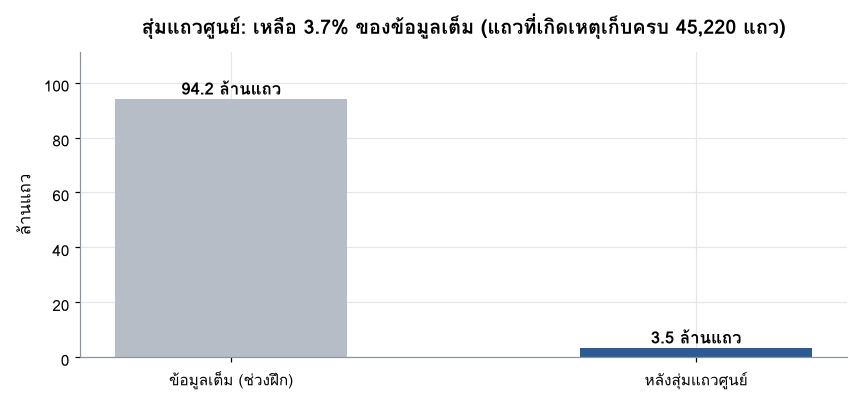

In [25]:
# รอบที่จะเทรนใหม่ในโน้ตบุ๊กนี้
FOLD = "2023H2"
fr = folds[(folds["unit"] == "6h") & (folds["fold_id"] == FOLD)].iloc[0]
# จำนวนวันฝึกของแต่ละช่วงเวลา (881 วัน)
T = np.array(json.loads(fr["train_dates_per_block"]))
# แกนวันที่ทั้งหมด
AX_DATES = pd.date_range("2021-01-01", "2025-12-31").strftime("%Y-%m-%d")
# แกนช่วงถนน เรียงตามรหัส (ลำดับเดียวกับ pipeline จริง)
SEGS = np.sort(uni["segment_id"].to_numpy())
# แปลงรหัสช่วงถนน → ลำดับ
seg_idx = pd.Series(np.arange(len(SEGS)), index=SEGS)
date_idx = pd.Series(np.arange(len(AX_DATES)), index=AX_DATES)
# ช่องที่เกิดเหตุ ในรูปลำดับ (d = วัน, s = ช่วงถนน, b = ช่วงเวลา, y = จำนวน)
pos = pd.DataFrame({"d": date_idx.reindex(c6["target_date"]).to_numpy(), "s": seg_idx.reindex(c6["segment_id"]).to_numpy(),
                    "b": pd.Series(range(4), index=BLOCKS).reindex(c6["time_block"]).to_numpy(), "y": c6["y_count"].to_numpy()})
# เฉพาะช่องที่อยู่ในช่วงฝึก
train_pos = pos[pos["d"] < T[pos["b"]]]
# K = 32, seed = 42 จาก config
K, SEED = EXP["sampling"]["max_zero_per_stratum"], EXP["sampling"]["seed"]

# seed ของแต่ละกลุ่ม: SHA-256 ของ seed|หน่วย|รอบ|ช่วงถนน|ช่วงเวลา (สูตรเดียวกับโน้ตบุ๊ก 20)
def stratum_seed(seg, block):
    return int(hashlib.sha256(f"{SEED}|6h|{FOLD}|{seg}|{block}".encode()).hexdigest()[:16], 16)

t0 = time.time()
# วันที่เกิดเหตุของแต่ละกลุ่ม (ช่วงถนน, ช่วงเวลา)
grp = {k: g["d"].to_numpy() for k, g in train_pos.sort_values(["s", "b", "d"]).groupby(["s", "b"])}
D, S_, Bk, W = [], [], [], []
# วนทุกกลุ่ม: 26,740 ช่วงถนน × 4 ช่วงเวลา
for s in range(len(SEGS)):
    for b in range(4):
        # วันที่เกิดเหตุของกลุ่มนี้
        pdays = grp.get((s, b), np.empty(0, np.int64))
        # nz = จำนวนวันไม่เกิดเหตุ, m = จำนวนที่จะสุ่ม (ไม่เกิน 32)
        nz = T[b] - len(pdays); m = min(K, nz)
        # ตัวสุ่มของกลุ่มนี้
        rng = np.random.default_rng(stratum_seed(SEGS[s], BLOCKS[b]))
        # วันไม่เกิดเหตุทั้งหมด แล้วสุ่มเลือก m วันแบบไม่ซ้ำ
        zd = np.setdiff1d(np.arange(T[b]), pdays, assume_unique=True)[np.sort(rng.choice(nz, m, replace=False))]
        # เก็บวัน ช่วงถนน ช่วงเวลา และน้ำหนัก nz/m
        D.append(zd); S_.append(np.full(m, s)); Bk.append(np.full(m, b)); W.append(np.full(m, nz / m))
# ตารางช่องศูนย์ที่สุ่มได้ (y = 0)
zeros = pd.DataFrame({"d": np.concatenate(D), "s": np.concatenate(S_), "b": np.concatenate(Bk), "y": 0.0, "w": np.concatenate(W)})
# ชุดฝึก = ช่องที่เกิดเหตุ (น้ำหนัก 1) + ช่องศูนย์ที่สุ่ม เรียงตามวัน ช่วงถนน ช่วงเวลา
sample = pd.concat([train_pos.assign(w=1.0, y=train_pos["y"].astype(float)), zeros], ignore_index=True).sort_values(["d", "s", "b"], kind="stable")
print(f"สุ่มเสร็จใน {time.time() - t0:.0f} วินาที")
# ผลการสุ่มของ pipeline จริง ใช้เทียบ
off = pd.read_csv(RUN20 / "sampling.csv").query("unit == '6h' and fold_id == @FOLD").iloc[0]
display(pd.DataFrame({"โน้ตบุ๊กนี้": [len(train_pos), len(zeros), len(sample), round(sample["w"].sum())],
                      "ผลทางการ (โน้ตบุ๊ก 20)": [off["positive_cells"], off["zero_cells_sampled"], off["sample_rows"], round(off["weighted_exposure"])]},
                     index=["แถวที่เกิดเหตุ", "แถวศูนย์ที่สุ่ม", "แถวฝึกทั้งหมด", "ผลรวมน้ำหนัก"]))

full_rows = len(SEGS) * T.sum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(["ข้อมูลเต็ม (ช่วงฝึก)", "หลังสุ่มแถวศูนย์"], [full_rows / 1e6, len(sample) / 1e6], color=[GREY, BLUE], width=.5)
for i, v in enumerate([full_rows, len(sample)]):
    ax.text(i, v / 1e6 + 1.5, f"{v / 1e6:,.1f} ล้านแถว", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, full_rows / 1e6 * 1.18); ax.set_ylabel("ล้านแถว")
ax.set_title(f"สุ่มแถวศูนย์: เหลือ {len(sample) / full_rows:.1%} ของข้อมูลเต็ม (แถวที่เกิดเหตุเก็บครบ {len(train_pos):,} แถว)")
plt.show()

### 8.2 เทรน HistGradientBoosting (`make_estimator` · โน้ตบุ๊ก 20)

| พารามิเตอร์ | ค่า | ความหมาย |
|---|---|---|
| `loss` | `poisson` | ทายเป็นจำนวนครั้ง และไม่ติดลบ |
| `max_iter` | 160 | จำนวนต้นไม้ที่ต่อกัน (boosting) |
| `learning_rate` | 0.05 | แต่ละต้นแก้ความผิดพลาดของต้นก่อนหน้าทีละน้อย |
| `max_leaf_nodes` / `min_samples_leaf` | 15 / 100 | ต้นไม้เล็ก ลดการจำข้อมูล (overfit) |
| `l2_regularization` | 5.0 | ลงโทษค่าที่สุดโต่ง |
| categorical | `route_code`, `time_block` | ใช้ `OrdinalEncoder` (เก็บ 255 สายที่พบบ่อย ที่เหลือรวมกลุ่ม) |

ค่าทั้งหมด **ล็อกไว้ใน config ก่อนดูผล** ไม่ได้ปรับตามผลทดสอบ

In [26]:
# เครื่องมือจาก scikit-learn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

# ตัวแปรตัวเลขของถนน เรียงตามแกนช่วงถนน
seg_static = uni.set_index("segment_id").loc[SEGS, STATIC[1:]].astype("float64").reset_index(drop=True)
# เลขสายทาง (categorical) เป็นข้อความ
seg_route = uni.set_index("segment_id").loc[SEGS, "route_code"].astype(str).to_numpy()
# ตัวแปรของวัน เรียงตามแกนวันที่
date_tab = dates.set_index("target_date").loc[AX_DATES, DATE_COLS].astype("float64").reset_index(drop=True)

# สร้างตารางตัวแปรจากลำดับ (วัน, ช่วงถนน, ช่วงเวลา)
def build_X(d, s, b):
    # ต่อ เลขสายทาง + ตัวแปรถนน + ตัวแปรวัน
    X = pd.concat([pd.DataFrame({"route_code": seg_route[s]}), seg_static.iloc[s].reset_index(drop=True),
                   date_tab.iloc[d].reset_index(drop=True)], axis=1)
    # เพิ่มช่วงเวลา
    X["time_block"] = np.asarray(BLOCKS, dtype=object)[b]
    # จัดลำดับคอลัมน์ให้ตรงกับตอนฝึกของ pipeline จริง
    return X[FEATURES_6H]

# พารามิเตอร์ HGB จาก config (loss = poisson, 160 ต้น ฯลฯ)
params = next(c for c in EXP["candidates"]["configs"] if c["config_id"] == "hgb_poisson_fixed")["params"]
# แยกตัวแปร categorical และตัวเลข
CATS = ["route_code", "time_block"]; NUMS = [c for c in FEATURES_6H if c not in CATS]
# โมเดล = ขั้นเตรียมข้อมูล + HGB
model = Pipeline([
    # categorical → เลขลำดับ (สูงสุด 255 ค่า ค่าที่ไม่รู้จักเป็น NaN)
    ("pre", ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                                                      max_categories=255, dtype=np.float64), CATS),
                               # ตัวเลขส่งตรงเข้าโมเดล
                               ("num", "passthrough", NUMS)], remainder="drop", sparse_threshold=0.0)),
    # HGB: บอกว่าคอลัมน์ไหนเป็น categorical และใส่พารามิเตอร์
    ("model", HistGradientBoostingRegressor(categorical_features=[True] * len(CATS) + [False] * len(NUMS), **params)),
])
# ตารางตัวแปรของชุดฝึก
Xtr = build_X(sample["d"].to_numpy(), sample["s"].to_numpy(), sample["b"].to_numpy())
print("ขนาดตารางฝึก:", Xtr.shape); display(Xtr.head(3))
t0 = time.time()
# <<เทรน>> y = จำนวนอุบัติเหตุ, น้ำหนัก = 1 หรือ nz/m
model.fit(Xtr, sample["y"].to_numpy(), model__sample_weight=sample["w"].to_numpy())
print(f"เทรนเสร็จใน {time.time() - t0:.0f} วินาที")

ขนาดตารางฝึก: (3467940, 34)
เทรนเสร็จใน 62 วินาที


,route_code,geom_mid_x_m,geom_mid_y_m,geom_mid_lon,geom_mid_lat,geom_length_m,geom_log_length_m,geom_bearing_sin,geom_bearing_cos,geom_straightness,geom_turning_rad_per_km,day_of_week,month,day_of_month,is_weekend,doy_sin,doy_cos,fest_songkran_dist,fest_songkran_in,fest_songkran_pre_1_3,fest_songkran_pre_4_7,fest_songkran_post_1_3,fest_songkran_post_4_7,fest_new_year_dist,fest_new_year_in,fest_new_year_pre_1_3,fest_new_year_pre_4_7,fest_new_year_post_1_3,fest_new_year_post_4_7,season_hot,season_wet,season_cool,bank_holiday_asof,time_block
0,3420,665369.160728,1.710763e+06,100.541460,15.468724,2000.0,7.600902,0.944948,-0.327222,0.999935,0.475720,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,00-06
1,1087,488405.866393,1.958431e+06,98.890655,17.712952,2000.0,7.600902,-0.964186,-0.265228,0.949501,1.557958,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,18-24
2,1087,486202.314654,1.953131e+06,98.869908,17.665026,2000.0,7.600902,0.502068,-0.864828,0.859075,4.954510,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,06-12


### 8.3 ตัวแปรไหนสำคัญ (Permutation importance)
สลับค่าของตัวแปรทีละตัวแบบสุ่ม แล้วดูว่า Poisson deviance แย่ลงเท่าไร ยิ่งแย่ลงมาก แปลว่าโมเดลพึ่งตัวแปรนั้นมาก (คำนวณจากแถวฝึกที่สุ่มมา 300,000 แถว เพื่อให้เร็ว)

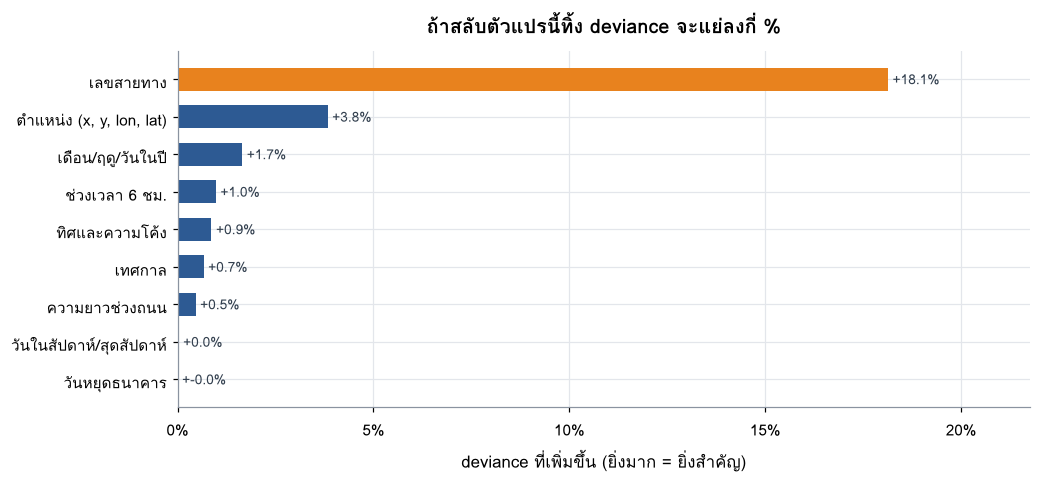

In [27]:
# deviance เฉลี่ยแบบถ่วงน้ำหนัก (ใช้ใน permutation importance)
def wdev(y, mu, w):
    mu = np.maximum(mu, 1e-12)
    return np.sum(w * 2 * (np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))) / np.sum(w)

rs = np.random.default_rng(0)
# สุ่ม 300,000 แถวเพื่อให้คำนวณเร็ว
ii = rs.choice(len(Xtr), 300_000, replace=False)
Xs, ys, ws = Xtr.iloc[ii].reset_index(drop=True), sample["y"].to_numpy()[ii], sample["w"].to_numpy()[ii]
# deviance ก่อนสลับตัวแปร
base_dev = wdev(ys, model.predict(Xs), ws)
# จัดตัวแปรเป็นกลุ่มตามความหมาย
groups = {"เลขสายทาง": ["route_code"], "ตำแหน่ง (x, y, lon, lat)": ["geom_mid_x_m", "geom_mid_y_m", "geom_mid_lon", "geom_mid_lat"],
          "ความยาวช่วงถนน": ["geom_length_m", "geom_log_length_m"], "ทิศและความโค้ง": ["geom_bearing_sin", "geom_bearing_cos", "geom_straightness", "geom_turning_rad_per_km"],
          "ช่วงเวลา 6 ชม.": ["time_block"], "วันในสัปดาห์/สุดสัปดาห์": ["day_of_week", "is_weekend"],
          "เดือน/ฤดู/วันในปี": ["month", "day_of_month", "doy_sin", "doy_cos", "season_hot", "season_wet", "season_cool"],
          "เทศกาล": [c for c in DATE_COLS if c.startswith("fest_")], "วันหยุดธนาคาร": ["bank_holiday_asof"]}
imp = {}
for g, cs in groups.items():
    Xp = Xs.copy()
    perm = rs.permutation(len(Xp))
    # สลับค่าของกลุ่มตัวแปรนี้แบบสุ่ม (ความสัมพันธ์กับ y หายไป)
    Xp[cs] = Xp[cs].to_numpy()[perm]
    # deviance แย่ลงกี่ % = ความสำคัญของกลุ่มนี้
    imp[g] = wdev(ys, model.predict(Xp), ws) / base_dev - 1
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(imp.index, imp.values, color=[AMBER if v == imp.max() else BLUE for v in imp.values], height=.62)
label_bars(ax, "+{:.1%}", horizontal=True, size=9); ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.xaxis.set_major_locator(plt.MultipleLocator(.05))
ax.set_xlim(0, imp.max() * 1.2); ax.set_title("ถ้าสลับตัวแปรนี้ทิ้ง deviance จะแย่ลงกี่ %"); ax.set_xlabel("deviance ที่เพิ่มขึ้น (ยิ่งมาก = ยิ่งสำคัญ)")
plt.show()
del Xtr, Xs, Xp

### 8.4 Baseline ที่โมเดลต้องเอาชนะ (`fit_baselines` · โน้ตบุ๊ก 20)

Baseline ที่ดีที่สุดคือ **`segment_mean_k365`**:

$$\hat y_{s,b} = \frac{C_{s,b} + k \cdot P_{s,b}}{N_{b} + k},\quad k = 365$$

- $C_{s,b}$ = จำนวนเหตุในช่วงฝึก
- $N_b$ = จำนวนวันฝึก
- $P_{s,b}$ = อัตราของ **ทั้งสายทาง** ต่อ กม. × ความยาวช่วงถนน

> 💡 ช่วงถนนส่วนใหญ่แทบไม่เคยเกิดเหตุ ถ้าใช้ค่าเฉลี่ยของช่วงนั้นเพียงอย่างเดียว ค่าจะแกว่งมาก จึง "ดึง" เข้าหาค่าของทั้งสายทาง (shrinkage) baseline นี้ใช้ **ข้อมูลฝึกเต็มทุกช่อง** ไม่ได้ใช้ข้อมูลที่สุ่ม

In [28]:
# ความยาวช่วงถนน (กม.)
km = uni.set_index("segment_id").loc[SEGS, "geom_length_m"].to_numpy() / 1000
# C = จำนวนอุบัติเหตุในช่วงฝึกของแต่ละ (ช่วงถนน, ช่วงเวลา)
C = np.zeros((len(SEGS), 4)); np.add.at(C, (train_pos["s"].to_numpy(), train_pos["b"].to_numpy()), train_pos["y"].to_numpy())
# สายทางของแต่ละช่วงถนน
routes, ri = np.unique(seg_route, return_inverse=True)
# รวมจำนวนเป็นระดับสายทาง
Cr = np.zeros((len(routes), 4)); np.add.at(Cr, ri, C)
# ความยาวรวมของแต่ละสายทาง
Lr = np.bincount(ri, weights=km)
# P = อัตราของสายทางต่อ กม. ต่อวัน × ความยาวช่วง
P = (Cr / (Lr[:, None] * T[None, :]))[ri] * km[:, None]
# baseline segment_mean_k365 = (C + 365·P) ÷ (N + 365)
BASE = (C + 365 * P) / (T[None, :] + 365)
display(pd.DataFrame(BASE[:3], columns=BLOCKS, index=SEGS[:3]).round(6))

,00-06,06-12,12-18,18-24
rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00000,0.0,0.0,0.0,0.0
rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00001,0.0,0.0,0.0,0.0
rsv1-rc315c7c508f:doh:1001:p0:c0:r2000:00000,0.0,0.0,0.0,0.0


---
# 9 · Evaluation — วัดผล

### 9.1 ตัวชี้วัด: Poisson deviance
$$\text{deviance}(y, \mu) = 2\left(y \log\frac{y}{\mu} - (y - \mu)\right) \qquad (y = 0 \Rightarrow 2\mu)$$

**ยิ่งต่ำยิ่งดี** ลงโทษหนักเมื่อเกิดเหตุจริงแต่โมเดลทายต่ำมาก ใช้ดูคู่กับ **MAE**

In [29]:
# Poisson deviance ของแต่ละช่อง (floor กัน log 0)
def poisson_deviance(y, mu, floor=1e-12):
    y, mu = np.asarray(y, float), np.maximum(np.asarray(mu, float), floor)
    return 2 * (np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0.0) - (y - mu))

# ตัวอย่าง 4 กรณี ให้เห็นว่า deviance ลงโทษแบบไหน
ex = pd.DataFrame({"y จริง": [0, 0, 1, 1], "ค่าที่ทาย μ": [0.001, 0.1, 0.001, 0.5]})
ex["deviance"] = poisson_deviance(ex["y จริง"], ex["ค่าที่ทาย μ"]).round(4)
display(ex)

,y จริง,ค่าที่ทาย μ,deviance
0,0,0.001,0.0020
1,0,0.100,0.2000
2,1,0.001,11.8175
3,1,0.500,0.3863


### 9.2 วัดผลรอบ 2023H2 ด้วยข้อมูลเต็ม 19.7 ล้านช่อง
ทำนาย **ทุกช่วงถนน × ทุกวัน (ก.ค.–ธ.ค. 2566) × 4 ช่วงเวลา** ทีละ 7 วัน (ใช้เวลาสักครู่)

In [30]:
# ช่วงวัดผลของรอบ 2023H2
e0, e1 = date_idx["2023-07-01"], date_idx["2023-12-31"]
# ช่องที่เกิดเหตุจริงในช่วงวัดผล
ev_pos = pos[(pos["d"] >= e0) & (pos["d"] <= e1)]
S, nS = np.arange(len(SEGS)), len(SEGS)
# ตัวสะสม [ผลรวม deviance, ผลรวม |y − μ|, ผลรวมค่าทาย]
acc = {"hgb": [0.0, 0.0, 0.0], "base": [0.0, 0.0, 0.0]}
by_block = np.zeros((2, 4)); n_block = np.zeros(4)
# ขอบของกลุ่มค่าทาย (สเกล log) สำหรับ calibration
CAL_EDGES = np.concatenate([[0], np.logspace(-5, -1, 17), [np.inf]])
cal = np.zeros((2, len(CAL_EDGES) - 1))                     # [ผลรวมค่าทาย, ผลรวมที่เกิดจริง] ต่อกลุ่มค่าทาย
daily = []
mu_store = []
t0 = time.time()
# ทำนายทีละ 7 วัน (7 × 26,740 × 4 ≈ 750,000 ช่อง) เพื่อไม่ให้ใช้หน่วยความจำมากเกินไป
for d0 in range(e0, e1 + 1, 7):
    dd = np.arange(d0, min(d0 + 7, e1 + 1))
    # สร้างทุกช่อง (วัน × ช่วงถนน × ช่วงเวลา) ของ 7 วันนี้
    d = np.repeat(dd, nS * 4); s = np.tile(np.repeat(S, 4), len(dd)); b = np.tile(np.arange(4), nS * len(dd))
    # ค่าทายของ HGB และของ baseline
    mu = model.predict(build_X(d, s, b)); mb = BASE[s, b]
    # ค่าจริง เริ่มเป็น 0 ทุกช่อง
    y = np.zeros(len(d))
    hit = ev_pos[(ev_pos["d"] >= dd[0]) & (ev_pos["d"] <= dd[-1])]
    if len(hit):
        # ใส่ค่า y ของช่องที่เกิดเหตุจริง
        y[(hit["d"].to_numpy() - dd[0]) * nS * 4 + hit["s"].to_numpy() * 4 + hit["b"].to_numpy()] = hit["y"].to_numpy()
    # สะสม deviance, ความคลาดเคลื่อน และผลรวมค่าทาย
    for k_, m_ in (("hgb", mu), ("base", mb)):
        acc[k_][0] += poisson_deviance(y, m_).sum(); acc[k_][1] += np.abs(y - m_).sum(); acc[k_][2] += m_.sum()
    # สะสม deviance แยกตามช่วงเวลา (ใช้ใน Error Analysis)
    for bi in range(4):
        sb = b == bi
        by_block[0, bi] += poisson_deviance(y[sb], mu[sb]).sum(); by_block[1, bi] += poisson_deviance(y[sb], mb[sb]).sum(); n_block[bi] += sb.sum()
    # จัดแต่ละช่องเข้ากลุ่มค่าทาย แล้วสะสมผลรวมค่าทายและค่าจริง
    idx = np.digitize(mu, CAL_EDGES) - 1
    cal[0] += np.bincount(idx, weights=mu, minlength=cal.shape[1]); cal[1] += np.bincount(idx, weights=y, minlength=cal.shape[1])
    # ผลรวมรายวันทั้งประเทศ (ค่าทาย และที่เกิดจริง)
    for j, day in enumerate(dd):
        sl = slice(j * nS * 4, (j + 1) * nS * 4)
        daily.append((AX_DATES[day], mu[sl].sum(), mb[sl].sum(), y[sl].sum()))
    # เก็บค่าทายไว้คำนวณจุดตัดสี
    mu_store.append(mu.astype(np.float32))
# จำนวนช่องทั้งหมดในช่วงวัดผล (19.7 ล้าน)
N = (e1 - e0 + 1) * nS * 4
print(f"ทำนายครบ {N:,} ช่องใน {time.time() - t0:.0f} วินาที | เกิดเหตุจริง {int(ev_pos['y'].sum()):,} ครั้ง")

# ตัวชี้วัดเฉลี่ย: deviance, MAE และอัตราส่วนผลรวม
res = pd.DataFrame({"mean Poisson deviance": [acc["hgb"][0] / N, acc["base"][0] / N], "MAE": [acc["hgb"][1] / N, acc["base"][1] / N],
                    "ผลรวมที่ทาย ÷ ที่เกิดจริง": [acc["hgb"][2] / ev_pos["y"].sum(), acc["base"][2] / ev_pos["y"].sum()]},
                   index=["HGB (เทรนในโน้ตบุ๊กนี้)", "Baseline segment_mean_k365"])
display(res)
# HGB ดีกว่า baseline กี่ %
gain = 1 - res.iloc[0, 0] / res.iloc[1, 0]
# ผลทางการของทุกรอบ ใช้เทียบ
fm = pd.read_csv(RUN20 / "fold_metrics.csv")
o = fm[(fm["unit"] == "6h") & (fm["fold_id"] == FOLD)].set_index("method")["mean_poisson_deviance"]
print(f"HGB ดีกว่า baseline: โน้ตบุ๊กนี้ {gain:.1%} | ผลทางการรอบเดียวกัน {1 - o['hgb_poisson_fixed::core'] / o['segment_mean_k365']:.1%}")

ทำนายครบ 19,680,640 ช่องใน 111 วินาที | เกิดเหตุจริง 9,171 ครั้ง
HGB ดีกว่า baseline: โน้ตบุ๊กนี้ 4.5% | ผลทางการรอบเดียวกัน 4.6%


,mean Poisson deviance,MAE,ผลรวมที่ทาย ÷ ที่เกิดจริง
HGB (เทรนในโน้ตบุ๊กนี้),0.006286,0.000897,0.932661
Baseline segment_mean_k365,0.006583,0.000949,1.045124


### 9.3 ค่าทำนายรวมรายวัน เทียบกับที่เกิดจริง
รวมค่าทำนายของทุกช่วงถนนในแต่ละวัน แล้วเทียบกับจำนวนที่เกิดจริงทั้งประเทศ (เส้นที่ทายควรขึ้นลงตามของจริง)

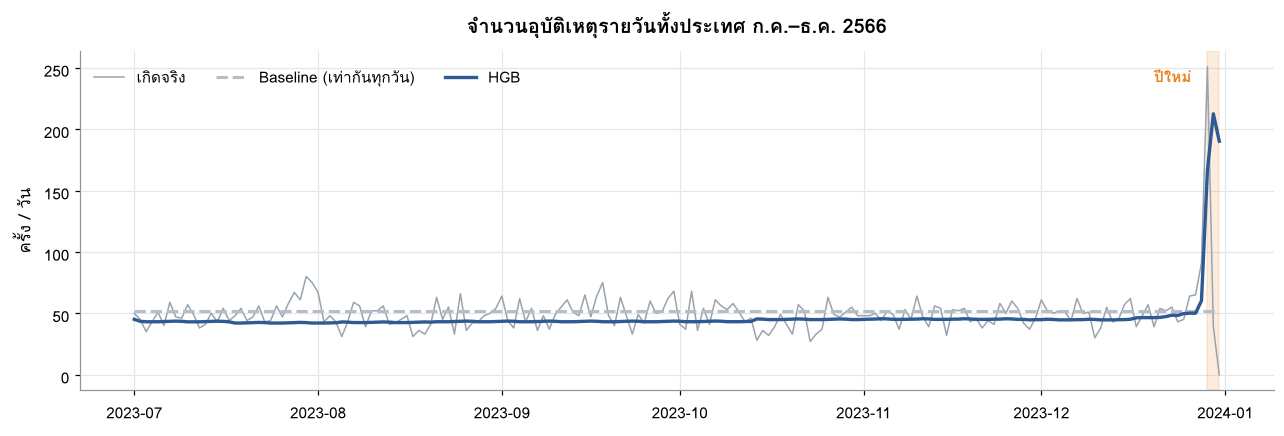

In [31]:
# ตารางผลรวมรายวัน
dl = pd.DataFrame(daily, columns=["date", "hgb", "base", "actual"]); dl["date"] = pd.to_datetime(dl["date"])
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dl["date"], dl["actual"], color="#9AA3AE", lw=1, label="เกิดจริง")
ax.plot(dl["date"], dl["base"], color=GREY, lw=2, ls="--", label="Baseline (เท่ากันทุกวัน)")
ax.plot(dl["date"], dl["hgb"], color=BLUE, lw=2.2, label="HGB")
ny = dl[dl["date"] >= "2023-12-29"]
ax.axvspan(pd.Timestamp("2023-12-29"), pd.Timestamp("2023-12-31"), color=AMBER, alpha=.15); ax.text(pd.Timestamp("2023-12-20"), dl["actual"].max() * .95, "ปีใหม่", color=AMBER, fontweight="bold")
ax.set_title("จำนวนอุบัติเหตุรายวันทั้งประเทศ ก.ค.–ธ.ค. 2566"); ax.set_ylabel("ครั้ง / วัน"); ax.legend(ncol=3, loc="upper left")
plt.show()

### 9.4 Calibration: ค่าที่ทายเชื่อได้แค่ไหน
จัดกลุ่มช่องตามค่าที่โมเดลทาย แล้วเทียบ **ค่าเฉลี่ยที่ทาย** กับ **ค่าเฉลี่ยที่เกิดจริง** ของแต่ละกลุ่ม ถ้าจุดอยู่บนเส้นทแยงแปลว่าค่าที่ทายเชื่อได้

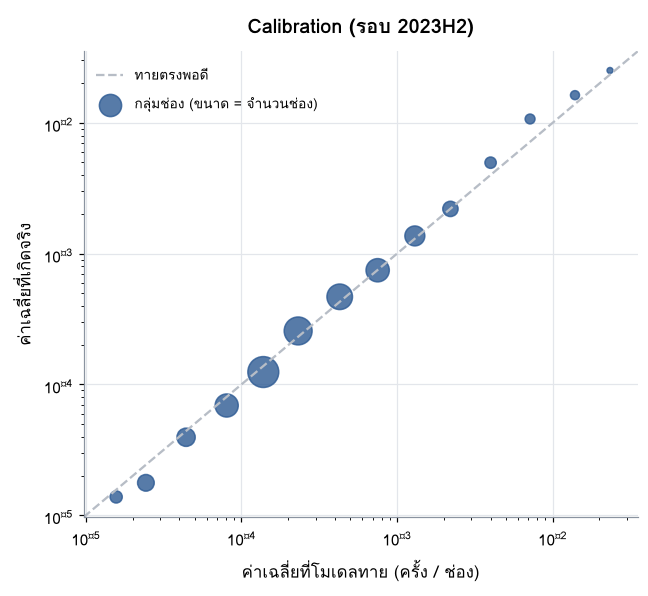

In [32]:
cnt_bins = np.zeros(cal.shape[1])
for mu in mu_store:
    cnt_bins += np.bincount(np.digitize(mu, CAL_EDGES) - 1, minlength=cal.shape[1])
# ใช้เฉพาะกลุ่มที่มีช่องมากพอ (เกิน 5,000 ช่อง)
okb = cnt_bins > 5000
# ค่าเฉลี่ยที่ทาย และค่าเฉลี่ยที่เกิดจริง ของแต่ละกลุ่ม
mp, ma = cal[0][okb] / cnt_bins[okb], cal[1][okb] / cnt_bins[okb]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
lim = [min(mp.min(), ma[ma > 0].min()) * .7, max(mp.max(), ma.max()) * 1.4]
ax.plot(lim, lim, "--", color=GREY, label="ทายตรงพอดี")
ax.scatter(mp, np.maximum(ma, lim[0]), s=np.sqrt(cnt_bins[okb]) / 6, color=BLUE, alpha=.8, label="กลุ่มช่อง (ขนาด = จำนวนช่อง)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("ค่าเฉลี่ยที่โมเดลทาย (ครั้ง / ช่อง)"); ax.set_ylabel("ค่าเฉลี่ยที่เกิดจริง"); ax.set_title("Calibration (รอบ 2023H2)"); ax.legend(loc="upper left", fontsize=9)
plt.show()

### 9.5 ผลทั้ง 4 รอบ (ผลทางการ)

ตัวเลขบนแท่ง = deviance ของ HGB ต่ำกว่า baseline กี่ % (สีแดง = แพ้)


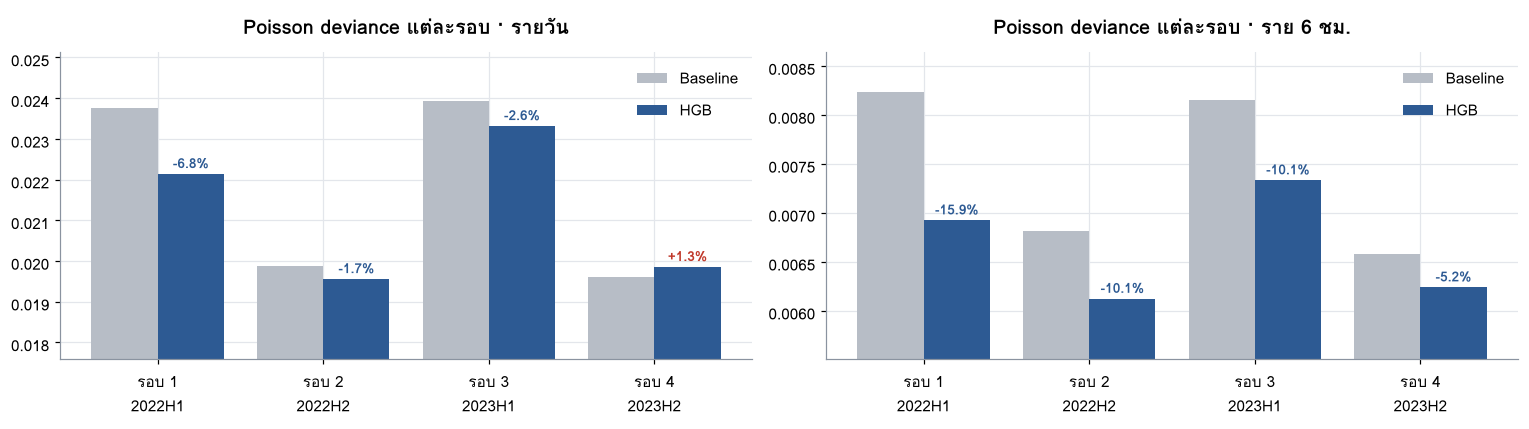

In [33]:
# ชื่อโมเดลที่ใช้จริงในผลทางการ
SELM = "hgb_poisson_fixed::routed_context"
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for a, unit, title in zip(axes, ["daily", "6h"], ["รายวัน", "ราย 6 ชม."]):
    p = fm[(fm["unit"] == unit) & fm["fold_id"].isin(["2022H1", "2022H2", "2023H1", "2023H2"])].pivot(index="fold_id", columns="method", values="mean_poisson_deviance")
    x = np.arange(len(p))
    a.bar(x - .2, p["segment_mean_k365"], .4, color=GREY, label="Baseline")
    a.bar(x + .2, p[SELM], .4, color=BLUE, label="HGB")
    for i in range(len(p)):
        g = 1 - p[SELM].iloc[i] / p["segment_mean_k365"].iloc[i]
        a.text(i + .2, p[SELM].iloc[i], f"-{g:.1%}" if g > 0 else f"+{-g:.1%}", ha="center", va="bottom", fontsize=9,
               color=BLUE if g > 0 else RED, fontweight="bold")
    a.set_xticks(x, [f"รอบ {i + 1}\n{f}" for i, f in enumerate(p.index)])
    a.set_ylim(p[[SELM, "segment_mean_k365"]].min().min() * .9, p[[SELM, "segment_mean_k365"]].max().max() * 1.05)
    a.set_title(f"Poisson deviance แต่ละรอบ · {title}"); a.legend(loc="upper right")
plt.tight_layout(); plt.show()
print("ตัวเลขบนแท่ง = deviance ของ HGB ต่ำกว่า baseline กี่ % (สีแดง = แพ้)")

---
# 10 · Error Analysis — ทำนายพลาดตรงไหน

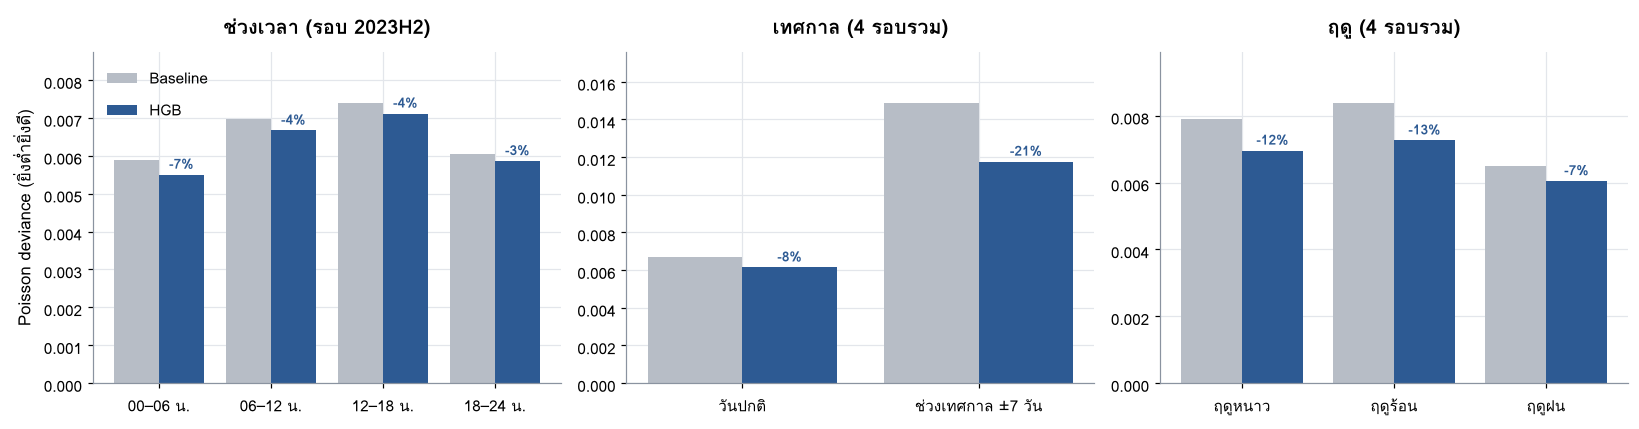

In [34]:
# deviance แยกตามช่วงเวลา
eb = pd.DataFrame({"HGB": by_block[0] / n_block, "Baseline": by_block[1] / n_block}, index=[BLOCK_TH[b] for b in BLOCKS])
# ผลทางการแยกตามกลุ่ม (เทศกาล ฤดู)
sm = pd.read_csv(RUN20 / "strata_metrics.csv")
def strat(stratum, mapping):
    t = sm[(sm["unit"] == "6h") & (sm["scope"] == "oof_2022_2023") & (sm["stratum"] == stratum) & sm["method"].isin([SELM, "segment_mean_k365"])]
    t = t.pivot_table(index="level", columns="method", values="mean_poisson_deviance")
    t.index = [mapping.get(str(i), str(i)) for i in t.index]
    return t.rename(columns={SELM: "HGB", "segment_mean_k365": "Baseline"})
fest_t = strat("festival_window", {"no": "วันปกติ", "yes": "ช่วงเทศกาล ±7 วัน"})
seas_t = strat("season", {"hot": "ฤดูร้อน", "wet": "ฤดูฝน", "cool": "ฤดูหนาว"})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, t, title in [(axes[0], eb, "ช่วงเวลา (รอบ 2023H2)"), (axes[1], fest_t, "เทศกาล (4 รอบรวม)"), (axes[2], seas_t, "ฤดู (4 รอบรวม)")]:
    x = np.arange(len(t))
    a.bar(x - .2, t["Baseline"], .4, color=GREY, label="Baseline"); a.bar(x + .2, t["HGB"], .4, color=BLUE, label="HGB")
    for i in range(len(t)):
        a.text(i + .2, t["HGB"].iloc[i], f"-{1 - t['HGB'].iloc[i] / t['Baseline'].iloc[i]:.0%}", ha="center", va="bottom", fontsize=9, color=BLUE, fontweight="bold")
    a.set_xticks(x, t.index); a.set_title(title); a.set_ylim(0, t.max().max() * 1.18)
axes[0].legend(loc="upper left"); axes[0].set_ylabel("Poisson deviance (ยิ่งต่ำยิ่งดี)")
plt.tight_layout(); plt.show()

**สิ่งที่เห็น:**
- ช่วงเทศกาลทำนายยากที่สุด (deviance สูง) แต่เป็นช่วงที่ HGB ชนะ baseline ห่างที่สุด เพราะ baseline ไม่รู้จักเทศกาล
- ฤดูฝนชนะน้อยที่สุด เพราะไม่มีข้อมูลฝนจริงในโมเดลหลัก

In [35]:
dg = pd.read_csv(RUN20 / "diagnostics_seen_2024_2025.csv")
t = dg.pivot_table(index=["unit", "year"], columns="role", values="mean_poisson_deviance")
t["HGB ดีกว่า"] = (1 - t["selected"] / t["strongest_baseline"]).map("{:.1%}".format)
print("ช่วงตรวจปี 2567–2568 (โมเดลที่ล็อกไว้ ไม่ได้ฝึกใหม่):"); display(t)

ช่วงตรวจปี 2567–2568 (โมเดลที่ล็อกไว้ ไม่ได้ฝึกใหม่):


role             selected  strongest_baseline HGB ดีกว่า
unit  year                                              
6h    seen_2024  0.006731            0.007307       7.9%
      seen_2025  0.007348            0.008076       9.0%
daily seen_2024  0.021461            0.021660       0.9%
      seen_2025  0.023467            0.024000       2.2%

---
# 11 · Model Selection — เลือกโมเดลด้วยเกณฑ์ที่ล็อกไว้ก่อน

เกณฑ์ใน `config/spatial_experiment_v4.json` (`select_unit` · โน้ตบุ๊ก 20):
1. deviance รวม 4 รอบลดลงจาก baseline ที่ดีที่สุด **≥ 1%**
2. MAE แย่ลงได้ **ไม่เกิน 2%**
3. ชนะ baseline **อย่างน้อย 3 ใน 4 รอบ**

ไม่ผ่านข้อใดข้อหนึ่ง → ใช้ baseline แทน

**ทำไม HGB:** รอบนำร่อง (โน้ตบุ๊ก 25, 3,105 ช่วงถนน) เทียบ Poisson Regression, Random Forest และ HGB แล้ว HGB ดีที่สุด จึงนำมารันทั้งประเทศ

,หน่วย,baseline ที่ดีที่สุด,ลด deviance,อัตราส่วน MAE,ชนะ,ผล
0,รายวัน,segment_mean_k365,2.65% ✓,0.9964 ✓,3/4 ✓,ใช้ HGB
1,ราย 6 ชม.,segment_mean_k365,10.62% ✓,0.9975 ✓,4/4 ✓,ใช้ HGB


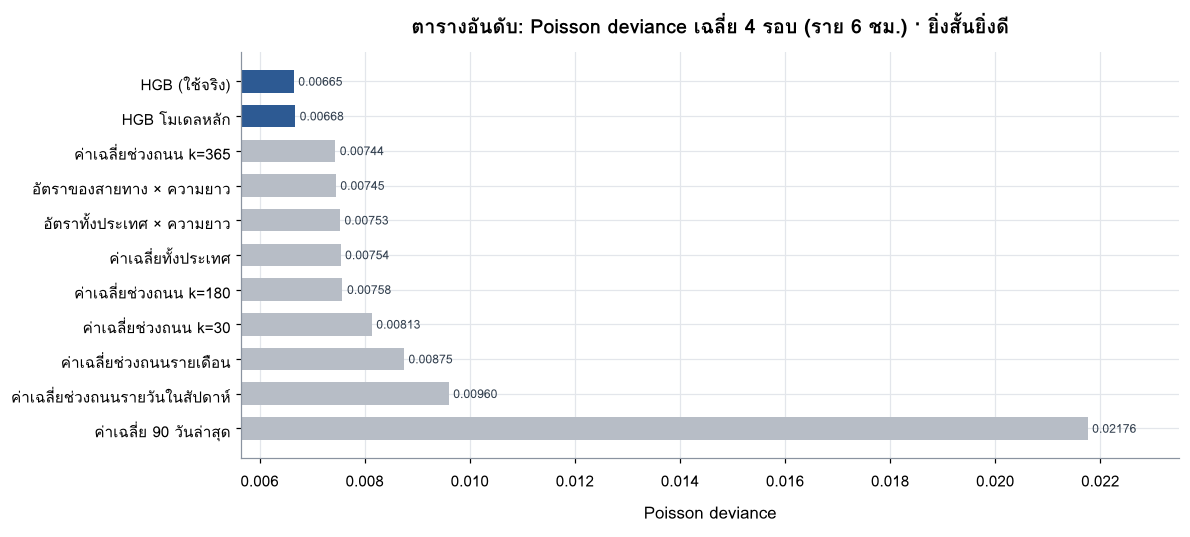

In [36]:
rows = []
for unit in ["daily", "6h"]:
    f = fm[(fm["unit"] == unit) & fm["fold_id"].isin(["2022H1", "2022H2", "2023H1", "2023H2"])]
    # รวม 4 รอบแบบถ่วงตามจำนวนช่อง (pooled)
    w = f.assign(dn=f["mean_poisson_deviance"] * f["n"], mn=f["mae"] * f["n"]).groupby("method")[["dn", "mn", "n"]].sum()
    pooled = pd.DataFrame({"dev": w["dn"] / w["n"], "mae": w["mn"] / w["n"]})
    # baseline ทุกแบบ (ไม่นับการทาย 0)
    bases = [m for m in pooled.index if "::" not in m and m != "zero"]
    # baseline ที่ดีที่สุด
    best = pooled.loc[bases, "dev"].idxmin()
    # เกณฑ์ข้อ 1 (ลด deviance) และข้อ 2 (อัตราส่วน MAE)
    red, ratio = 1 - pooled.loc[SELM, "dev"] / pooled.loc[best, "dev"], pooled.loc[SELM, "mae"] / pooled.loc[best, "mae"]
    per = f.pivot(index="fold_id", columns="method", values="mean_poisson_deviance")
    # เกณฑ์ข้อ 3: จำนวนรอบที่ชนะ
    wins = int((per[SELM] < per[best]).sum())
    rows.append({"หน่วย": "รายวัน" if unit == "daily" else "ราย 6 ชม.", "baseline ที่ดีที่สุด": best,
                 "ลด deviance": f"{red:.2%} {'✓' if red >= .01 else '✗'}", "อัตราส่วน MAE": f"{ratio:.4f} {'✓' if ratio <= 1.02 else '✗'}",
                 "ชนะ": f"{wins}/4 {'✓' if wins >= 3 else '✗'}", "ผล": "ใช้ HGB" if red >= .01 and ratio <= 1.02 and wins >= 3 else "ใช้ baseline"})
display(pd.DataFrame(rows))

lb = fm[(fm["unit"] == "6h") & fm["fold_id"].isin(["2022H1", "2022H2", "2023H1", "2023H2"])]
lb = lb.assign(dn=lb["mean_poisson_deviance"] * lb["n"]).groupby("method")[["dn", "n"]].sum()
lb = (lb["dn"] / lb["n"]).drop(["zero", "hgb_poisson_fixed::context"], errors="ignore").sort_values(ascending=False)
NAME = {"hgb_poisson_fixed::routed_context": "HGB (ใช้จริง)", "hgb_poisson_fixed::core": "HGB โมเดลหลัก", "segment_mean_k365": "ค่าเฉลี่ยช่วงถนน k=365",
        "segment_mean_k180": "ค่าเฉลี่ยช่วงถนน k=180", "segment_mean_k30": "ค่าเฉลี่ยช่วงถนน k=30", "route_length_rate": "อัตราของสายทาง × ความยาว",
        "global_length_rate": "อัตราทั้งประเทศ × ความยาว", "global_mean": "ค่าเฉลี่ยทั้งประเทศ", "segment_weekday_k10": "ค่าเฉลี่ยช่วงถนนรายวันในสัปดาห์",
        "segment_month_k30": "ค่าเฉลี่ยช่วงถนนรายเดือน", "recent90_segment": "ค่าเฉลี่ย 90 วันล่าสุด"}
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh([NAME.get(m, m) for m in lb.index], lb.values, color=[BLUE if "hgb" in m else GREY for m in lb.index], height=.65)
label_bars(ax, "{:.5f}", horizontal=True, size=8); ax.set_xlim(lb.min() * .85, lb.max() * 1.08)
ax.set_title("ตารางอันดับ: Poisson deviance เฉลี่ย 4 รอบ (ราย 6 ชม.) · ยิ่งสั้นยิ่งดี"); ax.set_xlabel("Poisson deviance")
plt.show()

### 11.1 จากค่าทำนายเป็น "สี" บนแผนที่ (`build_colour_contract` · โน้ตบุ๊ก 21)
1. ความหนาแน่น = ค่าทำนาย ÷ ความยาว (กม.) ช่วงสั้นกับช่วงยาวจะได้เทียบกันได้
2. **ส้ม (สูง)** = เกินเปอร์เซ็นไทล์ 80 (20% บนสุด) และ **แดง (สูงมาก)** = เกินเปอร์เซ็นไทล์ 95 (5% บนสุด) ของทั้งประเทศ
3. จุดตัดคงที่ทั้งประเทศ สีแดงบนถนนสายไหนก็มีความหมายเดียวกัน

> 💡 สีเป็นการ **เทียบกับถนนอื่น** ไม่ใช่ความน่าจะเป็นที่คนขับคนหนึ่งจะเกิดอุบัติเหตุ

,จุดตัด,โน้ตบุ๊กนี้ (2023H2),ผลทางการ (OOF 2565–2566)
0,ส้ม (P80),0.000269,0.000309
1,แดง (P95),0.000679,0.000770


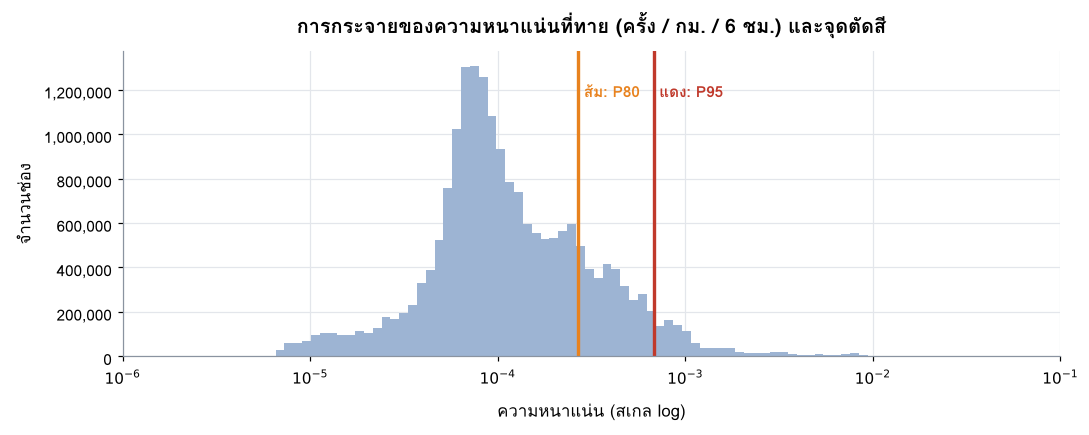

In [37]:
# ค่าทายทั้งหมดของรอบ 2023H2
mu_all = np.concatenate(mu_store)
# ความหนาแน่น = ค่าทาย ÷ ความยาว (กม.)
dens = mu_all / np.tile(np.repeat(km, 4), len(mu_all) // (nS * 4))
# จุดตัดสีส้ม (P80) และแดง (P95)
q80, q95 = np.quantile(dens, [.80, .95])
# จุดตัดสีทางการ (โน้ตบุ๊ก 21) ใช้เทียบ
cc = json.loads((RUN21 / "colour_contract_6h.json").read_text("utf-8"))
display(pd.DataFrame({"จุดตัด": ["ส้ม (P80)", "แดง (P95)"], "โน้ตบุ๊กนี้ (2023H2)": [q80, q95], "ผลทางการ (OOF 2565–2566)": cc["raw_cutoffs"][1:3]}))
fig, ax = plt.subplots(figsize=(11, 3.6))
lo = np.log10(np.clip(dens, 1e-6, None))
ax.hist(lo, bins=80, color=LIGHT)
for q, c, lab in [(q80, AMBER, "ส้ม: P80"), (q95, RED, "แดง: P95")]:
    ax.axvline(np.log10(q), color=c, lw=2.2); ax.text(np.log10(q) + .03, ax.get_ylim()[1] * .85, lab, color=c, fontweight="bold")
ax.set_xticks(range(-6, 0), [f"$10^{{{i}}}$" for i in range(-6, 0)]); commas(ax)
ax.set_title("การกระจายของความหนาแน่นที่ทาย (ครั้ง / กม. / 6 ชม.) และจุดตัดสี"); ax.set_xlabel("ความหนาแน่น (สเกล log)"); ax.set_ylabel("จำนวนช่อง")
plt.show()
del mu_all, dens, lo

---
# 12 · ทดสอบปี 2569 (โน้ตบุ๊ก 23)

ปี 2569 (ม.ค.–ก.ย.) เป็นข้อมูลที่ **โมเดลไม่เคยเห็น และไม่เคยใช้ปรับอะไรเลย** จึงเป็นการทดสอบที่ตรงที่สุด

ข้อมูลผ่านการทำความสะอาดและจับคู่ถนนแบบเดียวกัน เหลือ **15,425 รายการ** (จากไฟล์ล่าสุด 18,448 แถว)

> ⚠️ **วิธีวัดต่างจากขั้น 9:** ปี 2569 ยังไม่รู้ครบว่าช่องไหน "ไม่เกิดเหตุจริง" (อาจบันทึกเพิ่มภายหลัง) จึงวัดเฉพาะ **ช่องที่เกิดเหตุจริง** ว่าโมเดลให้ค่ากับจุดเหล่านั้นดีกว่า baseline แค่ไหน (deviance ยิ่งต่ำยิ่งดี)

HGB ดีกว่าทุกเดือน: True


,unit,group,ช่องที่เกิดเหตุ,deviance_floor_audit_selected,deviance_floor_audit_baseline,HGB ดีกว่า
0,daily,all,15011,9.262852,9.903833,6.5%
1038,6h,all,15202,11.843458,13.686493,13.5%


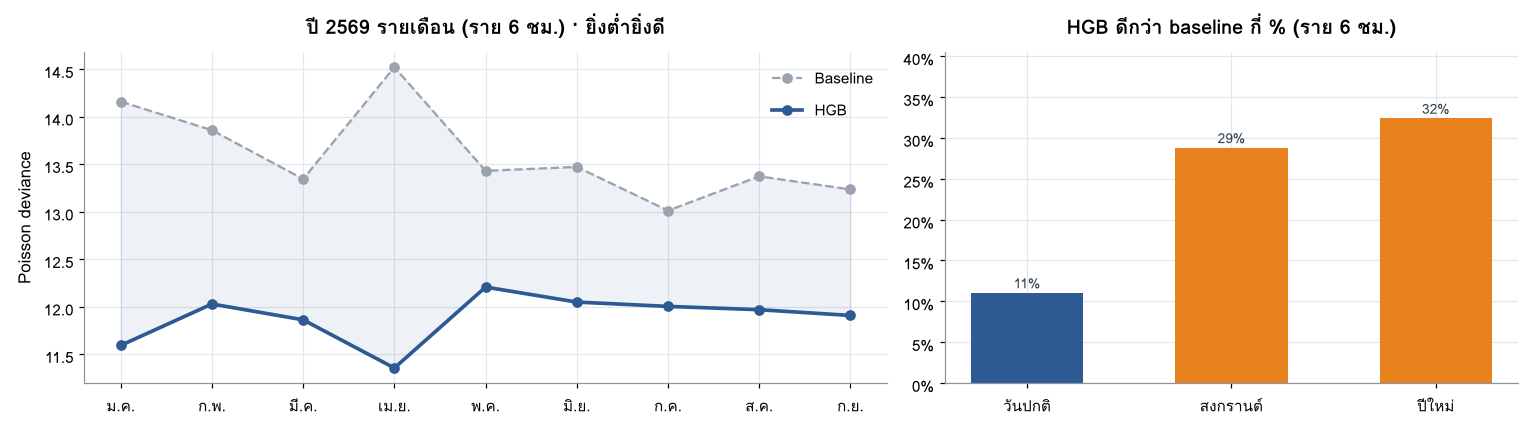

In [38]:
# ผลทดสอบปี 2569 จากโน้ตบุ๊ก 23
mc = pd.read_csv(RUN23 / "method_comparison.csv")
def table(dim):
    t = mc[mc["dim"] == dim][["unit", "group", "n_positive_cells", "deviance_floor_audit_selected", "deviance_floor_audit_baseline"]].copy()
    # HGB ดีกว่า baseline กี่ % (วัดที่ช่องที่เกิดเหตุจริง)
    t["HGB ดีกว่า"] = 1 - t["deviance_floor_audit_selected"] / t["deviance_floor_audit_baseline"]
    return t
ov = table("overall"); fe = table("festival")
display(ov.assign(**{"HGB ดีกว่า": ov["HGB ดีกว่า"].map("{:.1%}".format)}).rename(columns={"n_positive_cells": "ช่องที่เกิดเหตุ"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.4, 1]})
# ผลรายเดือนของโมเดลราย 6 ชม.
m6 = mc[(mc["dim"] == "month") & (mc["unit"] == "6h")].sort_values("group")
labels = [TH_MONTH[int(g[5:7]) - 1] for g in m6["group"]]
axes[0].plot(labels, m6["deviance_floor_audit_baseline"], "--o", color="#9AA3AE", label="Baseline")
axes[0].plot(labels, m6["deviance_floor_audit_selected"], "-o", color=BLUE, lw=2.4, label="HGB")
axes[0].fill_between(labels, m6["deviance_floor_audit_selected"], m6["deviance_floor_audit_baseline"], color=BLUE, alpha=.08)
axes[0].set_title("ปี 2569 รายเดือน (ราย 6 ชม.) · ยิ่งต่ำยิ่งดี"); axes[0].legend(); axes[0].set_ylabel("Poisson deviance")
f6_ = fe[fe["unit"] == "6h"].set_index("group").reindex(["none", "songkran_2026", "new_year_2026"])
axes[1].bar(["วันปกติ", "สงกรานต์", "ปีใหม่"], f6_["HGB ดีกว่า"], color=[BLUE, AMBER, AMBER], width=.55)
label_bars(axes[1], "{:.0%}"); axes[1].yaxis.set_major_formatter(PercentFormatter(1, 0)); axes[1].set_ylim(0, f6_["HGB ดีกว่า"].max() * 1.25)
axes[1].set_title("HGB ดีกว่า baseline กี่ % (ราย 6 ชม.)")
plt.tight_layout(); plt.show()
print("HGB ดีกว่าทุกเดือน:", bool((m6["deviance_floor_audit_selected"] < m6["deviance_floor_audit_baseline"]).all()))

---
# สรุป

| ขั้น | ผลลัพธ์ |
|---|---|
| Data | อุบัติเหตุ 2564–2568 **112,136** แถว + ถนน AADT อากาศ วันหยุด |
| Cleaning | เหลือ **106,308** แถว (ตรงกับ pipeline จริงทุกแถว) |
| EDA | เกิดบ่อยช่วง 12–18 น. วันหยุด สงกรานต์และปีใหม่ (≈ 3.6 เท่าของวันปกติ) กระจุกบนถนนส่วนน้อย |
| Preparation | **98,207** รายการบน **26,740** ช่วงถนน · 195 ล้านช่อง เป็นศูนย์ 99.95% · 34 ตัวแปร |
| Split | แบ่งตามเวลา 4 รอบ เว้น 30 วัน · ล็อกโมเดล ณ 1 ธ.ค. 2566 |
| Model | HistGradientBoosting (Poisson) + สุ่มแถวศูนย์พร้อมน้ำหนัก |
| Evaluation | ราย 6 ชม. deviance ต่ำกว่า baseline **10.6%** และชนะ **4/4** รอบ |
| ทดสอบ 2569 | ดีกว่า baseline **13.5%** (วัดที่ช่องเกิดเหตุจริง) ดีกว่าทุกเดือน และช่วงเทศกาลดีกว่ามากที่สุด |

**ข้อจำกัด**
- นับเฉพาะอุบัติเหตุที่ถูกบันทึกและจับคู่ถนนได้ และครอบคลุมเฉพาะทางหลวงกรมทางหลวง
- ไม่มีข้อมูลอากาศหลังปี 2566
- สีบนแผนที่เป็นการจัดอันดับเทียบกับถนนอื่น ไม่ใช่ความน่าจะเป็นของคนขับ
- ใช้วางแผนก่อนเดินทาง ไม่ใช่ระบบเตือนแบบ real-time